# 3. Modelado y agrupación de variables categóricas de alta cardinalidad (2022–2025)

**Entrada:** `dataset_modelo_prep` (109.020.828 registros, 30 columnas, Parquet particionado por `ANIO`), generado en `2_Preparación de los datos.ipynb`.  
**Objetivo de este cuaderno:** caracterizar y agrupar la totalidad de las variables categóricas de alta cardinalidad (`COD_TRANSFORMADOR` con ~37.346 categorías y `COD_CIRCUITO_LINEA` con ~1.097 categorías) en todo el panel 2022–2025, construyendo perfiles por transformador y por circuito y entrenando **dos modelos de *clustering* independientes** (`CLUSTER_CIRCUITO` y `CLUSTER_TRANSFORMADOR`) con cobertura del 100 % de los códigos del conjunto de datos y sin fuga de información hacia validación y prueba.

| Sección | Contenido |
|---|---|
| 0 | Librerías, parámetros declarados y funciones estadísticas |
| 1 | Carga de datos y partición determinista 70-15-15 (sin fuga del objetivo) |
| 2 | Construcción de los DataFrames de transformadores (`df_trafo_consumo` y `df_trafo_estratos`) |
| 3 | Diagnóstico descriptivo y tratamiento estadístico de datos atípicos (criterio de Tukey) |
| 4 | Caracterización de `COD_CIRCUITO_LINEA` (`df_circuitos`) y línea base de tamaño del efecto ($\eta^2$ y $arepsilon^2$) |
| 5 | Preprocesamiento estadístico, pruebas de asimetría y *clustering* independiente (`CLUSTER_CIRCUITO` y `CLUSTER_TRANSFORMADOR`) |
| 6 | Evaluación comparativa de retención de efecto y exportación de catálogos a Google Drive |

## Principios estadísticos y metodológicos del cuaderno

En coherencia estricta con los principios declarados en `2_Preparación de los datos.ipynb`:

1. **Cobertura estructural del 100 % sin fuga de información (esquema 70-15-15):**
   - La partición general del proyecto es **70 % entrenamiento, 15 % validación y 15 % prueba** sobre todos los años (2022–2025).
   - Para evitar fuga del objetivo (`KWH_DIA`) antes de materializar la partición física del modelado, se define una asignación determinista y reproducible 70-15-15 mediante el hash hexadecimal de `NIU_USUARIO`.
   - El inventario de códigos (`COD_TRANSFORMADOR`, `COD_CIRCUITO_LINEA`), la cantidad total de usuarios y la composición por estrato (`ESTRATO_SECTOR` 1 a 6) se registran sobre el 100 % del panel (no dependen del objetivo), mientras que **todos los estadísticos basados en el objetivo (`KWH_DIA_MEDIANA_USU`, `KWH_DIA_IQR_USU`, `PCT_CEROS`) y el ajuste de los modelos de *clustering* se calculan exclusivamente sobre el 70 % de entrenamiento (`ES_TRAIN_70 == 1`)**.
2. **Independencia por usuario y cuantiles exactos:**
   - La reducción intermedia en Dask agrega primero a nivel `(COD_TRANSFORMADOR, NIU_USUARIO)`, garantizando que cada usuario pese igual sin importar cuántos meses figure en el panel y permitiendo calcular cuantiles exactos ($Q_1$, mediana, $Q_3$, $\mathrm{IQR}$) en Pandas.
3. **Imputación por estrato cuando la dispersión inter-usuario es degenerada ($N \le 2$):**
   - En unidades con $N_{	ext{train}} \le 2$ usuarios, el rango intercuartílico entre usuarios (`KWH_DIA_IQR_USU`) es nulo o no estimable (lo que generaría clústeres artificiales con $\mathrm{IQR}=0$). Para $N_{	ext{train}} \le 2$ se asigna peso $w_{	ext{iqr}} = 0$, imputando directamente el $\mathrm{IQR}$ mediano de su `ESTRATO_DOMINANTE`, y para $N_{	ext{train}} \ge 3$ se aplica suavizamiento empírico (*Empirical Bayes*) con grados de libertad efectivos $N_{	ext{train}} - 2$.
4. **Desacoplamiento del estrato y centrado intra-estrato:**
   - En `CLUSTER_TRANSFORMADOR` se excluye la variable discreta `ESTRATO_DOMINANTE` de la matriz de distancias y se incorpora el **residuo de consumo respecto al estrato** ($\Delta	ext{kWh/día} = 	ext{Mediana}_{	ext{trafo}} - 	ext{Mediana}_{	ext{estrato}}$), capturando la variación intra-estrato sin duplicar una variable que ya entra al modelo predictivo. En `CLUSTER_CIRCUITO` se reemplaza la moda discreta por el **estrato promedio continuo** ($\sum_{e=1}^6 e \cdot p_e$) y la **entropía normalizada de Shannon**.
5. **Justificación estadística de transformaciones de simetrización ($\log(1+x)$):**
   - `RobustScaler` es una transformación lineal afín ($z_{	ext{rob}} = (x - Q_2)/\mathrm{IQR}$) que no corrige la asimetría positiva. Toda transformación previa $\log(1+x)$ se decide automáticamente midiendo el coeficiente de asimetría de Fisher–Pearson ($g_1$), la asimetría intercuartílica de Bowley ($S_B$) y el apalancamiento cuadrático máximo ($\max z_{	ext{rob}}^2$) en la función objetivo de `KMeans`.
6. **Tratamiento estadístico de datos atípicos sin umbrales arbitrarios:**
   - Los transformadores o circuitos con volumen o perfil extremo se identifican mediante los **límites de Tukey** $[Q_1 - k\,\mathrm{IQR},\; Q_3 + k\,\mathrm{IQR}]$ con análisis de sensibilidad en $k \in \{1,5;\; 2,0;\; 3,0\}$ y prueba de Mann–Whitney ($r$ rango-biserial). Para conservar el 100 % de cobertura sin distorsionar los centróides, el escalador y `KMeans` se ajustan (`fit`) sobre las unidades no atípicas (*inliers*) y las unidades atípicas se proyectan acotadas al límite de Tukey (`predict`), marcándolas con una bandera explícita en el catálogo.

## 0. Librerías, parámetros declarados y funciones estadísticas

Todos los umbrales metodológicos se declaran en esta sección y se evalúa su sensibilidad antes de tomar decisiones.

In [1]:
import os
import glob
import shutil
import warnings
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import dask
import dask.dataframe as dd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from google.colab import drive

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
pd.options.display.float_format = '{:,.4f}'.format
PALETA = ['#2C3E50', '#2980B9', '#27AE60', '#E67E22', '#C0392B', '#8E44AD']

In [2]:
# Parámetros generales y umbrales estadísticos declarados
DRIVE_ORIGEN          = '/content/drive/MyDrive/Superintendencia/dataset_modelo_prep'
LOCAL_ORIGEN          = './dataset_modelo_prep'
DIR_FIGURAS           = '/content/drive/MyDrive/Superintendencia/Figuras_3_Modelado_Categoricas'
DIR_CATALOGOS         = '/content/drive/MyDrive/Superintendencia/Catalogos_Categorias'

SEMILLA               = 42
ESTRATOS              = [1, 2, 3, 4, 5, 6]

# 1. Parámetros de la partición general 70-15-15 (todos los años 2022-2025)
FRAC_TRAIN            = 0.70
FRAC_VAL              = 0.15
FRAC_TEST             = 0.15
# Umbral entero sobre los primeros 4 dígitos hexadecimales de NIU_USUARIO (base 65.536)
UMBRAL_HEX_TRAIN      = int(round(FRAC_TRAIN * 65536))                  # 45.875 (70,00 %)
UMBRAL_HEX_VAL        = int(round((FRAC_TRAIN + FRAC_VAL) * 65536))     # 55.706 (85,00 %)

# 2. Parámetros de imputación de estrato y suavizamiento empírico (Empirical Bayes)
N_MIN_IQR             = 3       # Mínimo de usuarios en train para estimar IQR inter-usuario (gl = N - 2 >= 1)
M_SMOOTH_TRAFO        = 15.0    # Hiperparámetro de suavizamiento empírico hacia el estrato en transformadores
M_SMOOTH_CIRC         = 30.0    # Hiperparámetro de suavizamiento empírico hacia el estrato en circuitos

# 3. Parámetros de asimetría y detección de datos atípicos (criterio de Tukey)
UMBRAL_ASIMETRIA_G1   = 1.0     # |g1| > 1.0 indica asimetría fuerte (Bulmer, 1979) -> candidato a log(1 + x)
K_TUKEY_CANDIDATOS    = [1.5, 2.0, 3.0]
K_TUKEY_ELEGIDO       = 1.5     # Se verifica en análisis de sensibilidad (secciones 3.2 y 5.3)

In [3]:
def guardar_figura(fig, nombre):
    os.makedirs(DIR_FIGURAS, exist_ok=True)
    fig.savefig(os.path.join(DIR_FIGURAS, f'{nombre}.png'), dpi=150, bbox_inches='tight')


def comparar_grupos(a, b):
    """Prueba de Mann-Whitney y correlación rango-biserial r (idéntica a 2_Preparación de los datos.ipynb)."""
    a_clean = pd.Series(a).dropna().to_numpy(dtype='float64')
    b_clean = pd.Series(b).dropna().to_numpy(dtype='float64')
    if len(a_clean) == 0 or len(b_clean) == 0:
        return pd.Series({'n_a': len(a_clean), 'n_b': len(b_clean), 'mediana_a': np.nan,
                          'mediana_b': np.nan, 'p_valor': np.nan, 'r_rango_biserial': np.nan})
    u, p = stats.mannwhitneyu(a_clean, b_clean, alternative='two-sided')
    r_rb = 2.0 * u / (len(a_clean) * len(b_clean)) - 1.0
    return pd.Series({
        'n_a': len(a_clean),
        'n_b': len(b_clean),
        'mediana_a': np.median(a_clean),
        'mediana_b': np.median(b_clean),
        'p_valor': p,
        'r_rango_biserial': r_rb
    })


def diagnostico_asimetria_y_apalancamiento(df_in, columnas):
    """
    Calcula para cada variable en escala original y en escala log(1 + x):
    - Asimetría de Fisher-Pearson (g1)
    - Asimetría intercuartílica de Bowley (S_B)
    - Máximo valor absoluto tras RobustScaler (max |z_rob|) y apalancamiento cuadrático (max z_rob^2)
    """
    filas = []
    for col in columnas:
        x = df_in[col].dropna().to_numpy(dtype='float64')
        q1, q2, q3 = np.percentile(x, [25, 50, 75])
        iqr = max(q3 - q1, 1e-9)
        g1_raw = stats.skew(x, bias=False)
        sb_raw = ((q3 - q2) - (q2 - q1)) / iqr
        z_raw_max = np.max(np.abs((x - q2) / iqr))

        if np.min(x) >= 0:
            x_log = np.log1p(x)
            q1_l, q2_l, q3_l = np.percentile(x_log, [25, 50, 75])
            iqr_l = max(q3_l - q1_l, 1e-9)
            g1_log = stats.skew(x_log, bias=False)
            sb_log = ((q3_l - q2_l) - (q2_l - q1_l)) / iqr_l
            z_log_max = np.max(np.abs((x_log - q2_l) / iqr_l))
            aplicar_log = bool((abs(g1_raw) > UMBRAL_ASIMETRIA_G1) and (abs(g1_log) < abs(g1_raw)) and (z_log_max < z_raw_max))
        else:
            g1_log, sb_log, z_log_max, aplicar_log = np.nan, np.nan, np.nan, False

        filas.append({
            'Variable': col,
            'g1_original': g1_raw,
            'Bowley_original': sb_raw,
            'max_|z_rob|_original': z_raw_max,
            'max_z2_original': z_raw_max ** 2,
            'g1_log1p': g1_log,
            'Bowley_log1p': sb_log,
            'max_|z_rob|_log1p': z_log_max,
            'max_z2_log1p': z_log_max ** 2 if not np.isnan(z_log_max) else np.nan,
            'Transformar_log1p': aplicar_log
        })
    return pd.DataFrame(filas).set_index('Variable')


def aplicar_transformaciones_verificadas(df_in, tabla_diag, mapeo_salida):
    """
    Aplica log(1 + x) únicamente a las variables donde Transformar_log1p == True en tabla_diag;
    de lo contrario conserva la escala original, garantizando que toda transformación obedezca a la prueba estadística.
    """
    for col_orig, col_dest in mapeo_salida.items():
        usar_log = bool(tabla_diag.loc[col_orig, 'Transformar_log1p'])
        if usar_log:
            df_in[col_dest] = np.log1p(np.clip(df_in[col_orig], 0.0, None))
        else:
            df_in[col_dest] = df_in[col_orig].astype('float64')


def limites_tukey_serie(serie, k_lista=K_TUKEY_CANDIDATOS, usar_log=True):
    """Evalúa los límites superiores e inferiores de Tukey en escala original o log(1 + x)."""
    x = serie.dropna().to_numpy(dtype='float64')
    s_eval = np.log1p(np.clip(x, 0, None)) if usar_log else x
    q1, q2, q3 = np.percentile(s_eval, [25, 50, 75])
    iqr = q3 - q1
    res = {}
    for k in k_lista:
        lo_s, hi_s = q1 - k * iqr, q3 + k * iqr
        lo = np.expm1(lo_s) if usar_log else lo_s
        hi = np.expm1(hi_s) if usar_log else hi_s
        res[k] = (max(0.0, lo) if np.min(x) >= 0 else lo, hi)
    return res

## 1. Carga de datos y partición determinista 70-15-15 (Todos los años 2022–2025)

El conjunto preparado `dataset_modelo_prep` se encuentra particionado por `ANIO` (`2022` a `2025`).  
Dado que la validación y prueba del proyecto se definirán mediante una **partición general 70-15-15 de todos los años**, y dicha partición aún no se ha materializado en archivos separados, se construye una **partición determinista basada en los primeros 4 dígitos hexadecimales de `NIU_USUARIO`**:
- `TRAIN` (70 %): `int(NIU_USUARIO[:4], 16) < 45875`
- `VAL` (15 %): `45875 <= int(NIU_USUARIO[:4], 16) < 55706`
- `TEST` (15 %): `int(NIU_USUARIO[:4], 16) >= 55706`

De esta forma:
1. Todos los transformadores y circuitos del panel 2022–2025 quedan inventariados al 100 %.
2. Los estadísticos que usan `KWH_DIA` se estiman **únicamente sobre el 70 % de entrenamiento**, garantizando cero fuga de información cuando se evalúe en el 15 % de validación y 15 % de prueba.

In [4]:
drive.mount('/content/drive')

archivos_drive = sorted(glob.glob(os.path.join(DRIVE_ORIGEN, '**', '*.parquet'), recursive=True))
print(f'Archivos parquet encontrados en Drive: {len(archivos_drive):,}')

def _copiar_preservando_particion(ruta_origen):
    rel = os.path.relpath(ruta_origen, DRIVE_ORIGEN)
    ruta_destino = os.path.join(LOCAL_ORIGEN, rel)
    os.makedirs(os.path.dirname(ruta_destino), exist_ok=True)
    if not os.path.exists(ruta_destino):
        shutil.copy2(ruta_origen, ruta_destino)

with ThreadPoolExecutor(max_workers=8) as ex:
    list(ex.map(_copiar_preservando_particion, archivos_drive))

print('Copia local completada en:', LOCAL_ORIGEN)

Mounted at /content/drive
Archivos parquet encontrados en Drive: 734
Copia local completada en: ./dataset_modelo_prep


In [5]:
df = dd.read_parquet(LOCAL_ORIGEN)
df['ANIO'] = df['ANIO'].astype('int16')

n_total = len(df)
print(f'Total registros cargados (2022–2025): {n_total:,}')

Total registros cargados (2022–2025): 109,020,828


In [6]:
# Verificación de cardinalidad en la totalidad del dataset (2022–2025)
n_trafos, n_circuitos, n_usuarios = dask.compute(
    df['COD_TRANSFORMADOR'].nunique(),
    df['COD_CIRCUITO_LINEA'].nunique(),
    df['NIU_USUARIO'].nunique()
)
pd.Series({
    'Usuarios únicos (2022–2025)': n_usuarios,
    'Transformadores únicos (COD_TRANSFORMADOR)': n_trafos,
    'Circuitos únicos (COD_CIRCUITO_LINEA)': n_circuitos
}, name='Conteo total (2022–2025)')

,Conteo total (2022–2025)
Usuarios únicos (2022–2025),2410650
Transformadores únicos (COD_TRANSFORMADOR),37346
Circuitos únicos (COD_CIRCUITO_LINEA),1131


## 2. Construcción de los DataFrames de transformadores (`df_trafo_consumo` y `df_trafo_estratos`)

### 2.1 Reducción intermedia en Dask a nivel `(COD_TRANSFORMADOR, NIU_USUARIO)` y separación 70-15-15
Al reducir en Dask a un registro por `(COD_TRANSFORMADOR, NIU_USUARIO)`, asignamos a cada usuario su partición determinista (`TRAIN`, `VAL`, `TEST`) a partir del hash `NIU_USUARIO`:
- **Variables estructurales (sin usar el objetivo):** `COD_CIRCUITO_LINEA`, `N_USUARIOS`, `N_REGISTROS` y el desglose por estrato (`CANT_ESTRATO_1` … `CANT_ESTRATO_6`, `ESTRATO_DOMINANTE`, `PUREZA_ESTRATO_PCT`) se contabilizan sobre el 100 % de los usuarios del transformador.
- **Variables de respuesta energética (usan `KWH_DIA`):** `KWH_DIA_MEDIA_USU`, `KWH_DIA_MEDIANA_USU`, `KWH_DIA_STD_USU`, `KWH_DIA_Q1_USU`, `KWH_DIA_Q3_USU`, `KWH_DIA_IQR_USU` y `PCT_CEROS` se calculan **exclusivamente sobre los usuarios pertenecientes al 70 % de entrenamiento (`PARTICION == 'TRAIN'`)**.

In [7]:
cols_base = ['COD_TRANSFORMADOR', 'COD_CIRCUITO_LINEA', 'NIU_USUARIO', 'ESTRATO_SECTOR', 'KWH_DIA']
sub = df[cols_base].assign(ES_CERO=(df['KWH_DIA'] == 0).astype('int8'))

# Agregación por (COD_TRANSFORMADOR, NIU_USUARIO) en Dask
usuarios_trafo = (
    sub.groupby(['COD_TRANSFORMADOR', 'NIU_USUARIO'])
    .agg(
        COD_CIRCUITO_LINEA=('COD_CIRCUITO_LINEA', 'last'),
        ESTRATO_SECTOR=('ESTRATO_SECTOR', 'last'),
        N_MESES_USUARIO=('KWH_DIA', 'count'),
        SUMA_KWH_DIA=('KWH_DIA', 'sum'),
        KWH_DIA_USUARIO_MEDIA=('KWH_DIA', 'mean'),
        KWH_DIA_USUARIO_MIN=('KWH_DIA', 'min'),
        KWH_DIA_USUARIO_MAX=('KWH_DIA', 'max'),
        N_CEROS_USUARIO=('ES_CERO', 'sum')
    )
    .compute()
    .reset_index()
)

usuarios_trafo['ESTRATO_SECTOR'] = usuarios_trafo['ESTRATO_SECTOR'].astype('int8')

# Asignación determinista 70-15-15 mediante los primeros 4 caracteres hexadecimales del hash NIU_USUARIO
hex_val = usuarios_trafo['NIU_USUARIO'].str.slice(0, 4).apply(lambda s: int(s, 16)).to_numpy(dtype='int32')
usuarios_trafo['PARTICION'] = np.select(
    [hex_val < UMBRAL_HEX_TRAIN, hex_val < UMBRAL_HEX_VAL],
    ['TRAIN', 'VAL'],
    default='TEST'
)
usuarios_trafo['ES_TRAIN_70'] = (usuarios_trafo['PARTICION'] == 'TRAIN').astype('int8')

# Verificación de proporciones de la partición 70-15-15
resumen_particion = (
    usuarios_trafo.groupby('PARTICION')
    .agg(
        Pares_Usuario_Trafo=('NIU_USUARIO', 'count'),
        Registros_Facturas=('N_MESES_USUARIO', 'sum'),
        Transformadores_Presentes=('COD_TRANSFORMADOR', 'nunique')
    )
)
resumen_particion['% Usuarios'] = resumen_particion['Pares_Usuario_Trafo'] / len(usuarios_trafo) * 100
resumen_particion['% Registros'] = resumen_particion['Registros_Facturas'] / resumen_particion['Registros_Facturas'].sum() * 100
print(f"Total pares (COD_TRANSFORMADOR, NIU_USUARIO): {len(usuarios_trafo):,} | Transformadores únicos: {usuarios_trafo['COD_TRANSFORMADOR'].nunique():,}")
resumen_particion.loc[['TRAIN', 'VAL', 'TEST']]

Total pares (COD_TRANSFORMADOR, NIU_USUARIO): 2,479,611 | Transformadores únicos: 37,346


,Pares_Usuario_Trafo,Registros_Facturas,Transformadores_Presentes,% Usuarios,% Registros
PARTICION,,,,,
TRAIN,1734694,76268225,35699,69.9583,69.9575
VAL,372502,16363756,29897,15.0226,15.0098
TEST,372415,16388847,30063,15.0191,15.0328


### 2.2 DataFrame 1 (`df_trafo_consumo`): Perfil de consumo diario (entrenamiento 70 %) y escala por transformador

In [8]:
# 1. Estructura completa de los 37.346 transformadores (100 % de cobertura, sin usar KWH_DIA)
g_trafo_all = usuarios_trafo.groupby('COD_TRANSFORMADOR')
df_trafo_estructura = g_trafo_all.agg(
    COD_CIRCUITO_LINEA=('COD_CIRCUITO_LINEA', 'last'),
    N_USUARIOS=('NIU_USUARIO', 'count'),
    N_REGISTROS=('N_MESES_USUARIO', 'sum'),
)

# 2. Estadísticos de consumo calculados EXCLUSIVAMENTE sobre el 70 % de entrenamiento (sin fuga a VAL/TEST)
usuarios_train = usuarios_trafo.loc[usuarios_trafo['ES_TRAIN_70'] == 1]
g_trafo_train = usuarios_train.groupby('COD_TRANSFORMADOR')

df_trafo_train_stats = g_trafo_train.agg(
    N_USUARIOS_TRAIN=('NIU_USUARIO', 'count'),
    N_REGISTROS_TRAIN=('N_MESES_USUARIO', 'sum'),
    KWH_DIA_MEDIA_USU=('KWH_DIA_USUARIO_MEDIA', 'mean'),
    KWH_DIA_MEDIANA_USU=('KWH_DIA_USUARIO_MEDIA', 'median'),
    KWH_DIA_STD_USU=('KWH_DIA_USUARIO_MEDIA', 'std'),
    SUMA_KWH_DIA_TRAFO=('SUMA_KWH_DIA', 'sum'),
    KWH_DIA_MIN=('KWH_DIA_USUARIO_MIN', 'min'),
    KWH_DIA_MAX=('KWH_DIA_USUARIO_MAX', 'max'),
    TOTAL_CEROS=('N_CEROS_USUARIO', 'sum'),
)

df_trafo_train_stats['KWH_DIA_Q1_USU'] = g_trafo_train['KWH_DIA_USUARIO_MEDIA'].quantile(0.25)
df_trafo_train_stats['KWH_DIA_Q3_USU'] = g_trafo_train['KWH_DIA_USUARIO_MEDIA'].quantile(0.75)
df_trafo_train_stats['KWH_DIA_IQR_USU'] = df_trafo_train_stats['KWH_DIA_Q3_USU'] - df_trafo_train_stats['KWH_DIA_Q1_USU']

# Unión al inventario completo de transformadores
df_trafo_consumo = df_trafo_estructura.join(df_trafo_train_stats, how='left')
df_trafo_consumo['N_USUARIOS_TRAIN'] = df_trafo_consumo['N_USUARIOS_TRAIN'].fillna(0).astype('int32')
df_trafo_consumo['N_REGISTROS_TRAIN'] = df_trafo_consumo['N_REGISTROS_TRAIN'].fillna(0).astype('int32')
df_trafo_consumo['TOTAL_CEROS'] = df_trafo_consumo['TOTAL_CEROS'].fillna(0).astype('int32')
df_trafo_consumo['KWH_DIA_STD_USU'] = df_trafo_consumo['KWH_DIA_STD_USU'].fillna(0.0)

df_trafo_consumo['KWH_DIA_MEDIA_REG'] = (
    df_trafo_consumo['SUMA_KWH_DIA_TRAFO'] / df_trafo_consumo['N_REGISTROS_TRAIN'].replace(0, np.nan)
)
df_trafo_consumo['KWH_DIA_TOTAL_TRAFO'] = df_trafo_consumo['KWH_DIA_MEDIA_USU'] * df_trafo_consumo['N_USUARIOS']
df_trafo_consumo['PCT_CEROS'] = (
    df_trafo_consumo['TOTAL_CEROS'] / df_trafo_consumo['N_REGISTROS_TRAIN'].replace(0, np.nan)
) * 100.0

cols_orden_consumo = [
    'COD_CIRCUITO_LINEA', 'N_USUARIOS', 'N_USUARIOS_TRAIN', 'N_REGISTROS', 'N_REGISTROS_TRAIN',
    'KWH_DIA_MEDIA_USU', 'KWH_DIA_MEDIANA_USU', 'KWH_DIA_STD_USU',
    'KWH_DIA_Q1_USU', 'KWH_DIA_Q3_USU', 'KWH_DIA_IQR_USU',
    'KWH_DIA_MEDIA_REG', 'KWH_DIA_TOTAL_TRAFO',
    'KWH_DIA_MIN', 'KWH_DIA_MAX', 'TOTAL_CEROS', 'PCT_CEROS'
]
df_trafo_consumo = df_trafo_consumo[cols_orden_consumo].sort_values('N_USUARIOS', ascending=False)

n_sin_train = int((df_trafo_consumo['N_USUARIOS_TRAIN'] == 0).sum())
print(f'df_trafo_consumo: {df_trafo_consumo.shape[0]:,} transformadores | Sin lecturas en TRAIN (se imputarán por estrato): {n_sin_train:,}')
df_trafo_consumo.head(10)

df_trafo_consumo: 37,346 transformadores | Sin lecturas en TRAIN (se imputarán por estrato): 1,647


,COD_CIRCUITO_LINEA,N_USUARIOS,N_USUARIOS_TRAIN,N_REGISTROS,N_REGISTROS_TRAIN,KWH_DIA_MEDIA_USU,KWH_DIA_MEDIANA_USU,KWH_DIA_STD_USU,KWH_DIA_Q1_USU,KWH_DIA_Q3_USU,KWH_DIA_IQR_USU,KWH_DIA_MEDIA_REG,KWH_DIA_TOTAL_TRAFO,KWH_DIA_MIN,KWH_DIA_MAX,TOTAL_CEROS,PCT_CEROS
COD_TRANSFORMADOR,,,,,,,,,,,,,,,,,
1016B00000,,18246,12704,32428,22114,1.7145,0.1780,3.2719,0.0625,2.3333,2.2708,2.3413,"31,283.4058",0.0000,48.6429,3239,14.6468
100ET70000,0257,3017,2108,20124,14252,2.1003,1.6040,2.2553,0.3447,3.0719,2.7271,3.1646,"6,336.7270",0.0000,47.2759,1101,7.7252
101QZX0000,,1404,980,39950,27675,2.2508,2.1341,1.2955,1.4545,3.0278,1.5732,2.2611,"3,160.1454",0.0000,18.0909,2069,7.4761
96954TR1,0147,1357,956,8849,6248,3.6005,3.1296,3.2400,1.6337,5.0143,3.3805,3.5217,"4,885.9134",0.0000,48.2188,867,13.8764
100TWK0000,0237,1319,932,12357,8718,0.9534,0.6541,1.2684,0.0532,1.3633,1.3102,1.1783,"1,257.5677",0.0000,23.2258,2803,32.1519
91669TR1,,1310,924,7844,5531,1.6083,1.5570,1.2203,0.8391,2.2175,1.3784,1.6088,"2,106.9042",0.0000,26.6667,620,11.2095
101QT30000,,1293,939,1769,1295,1.6239,1.4333,1.1971,0.8333,2.2000,1.3667,1.4599,"2,099.7642",0.0000,15.0333,373,28.8031
101OGO0000,,1212,828,57981,39590,2.4365,2.3095,1.2033,1.6903,2.9962,1.3058,2.4402,"2,952.9932",0.0000,47.4138,2973,7.5095
101QYS0000,,1201,836,25901,17912,1.3742,1.2731,1.2894,0.0606,2.2545,2.1939,1.8544,"1,650.4297",0.0000,36.0000,2389,13.3374


### 2.3 DataFrame 2 (`df_trafo_estratos`): Composición por estrato (1 a 6) e imputación por estrato

In [9]:
# Conteo estructural de usuarios únicos por (COD_TRANSFORMADOR, ESTRATO_SECTOR) — no depende de KWH_DIA
conteo_estratos = (
    usuarios_trafo.groupby(['COD_TRANSFORMADOR', 'ESTRATO_SECTOR'])['NIU_USUARIO']
    .count()
    .unstack(fill_value=0)
    .reindex(columns=ESTRATOS, fill_value=0)
)
conteo_estratos.columns = [f'CANT_ESTRATO_{e}' for e in ESTRATOS]

total_usu = conteo_estratos.sum(axis=1)
pct_estratos = conteo_estratos.div(total_usu, axis=0) * 100.0
pct_estratos.columns = [f'PCT_ESTRATO_{e}' for e in ESTRATOS]

# Estrato dominante (moda), estrato promedio continuo, pureza y entropía normalizada de Shannon
estrato_dom = conteo_estratos.values.argmax(axis=1) + 1
pesos_estrato = pct_estratos.to_numpy(dtype='float64') / 100.0
estrato_promedio = (pesos_estrato * np.array(ESTRATOS, dtype='float64')).sum(axis=1)
pureza_estrato = pct_estratos.max(axis=1)
n_estratos_presentes = (conteo_estratos > 0).sum(axis=1)

with np.errstate(divide='ignore', invalid='ignore'):
    entropia_trafo = -np.nansum(np.where(pesos_estrato > 0, pesos_estrato * np.log(pesos_estrato), 0.0), axis=1) / np.log(len(ESTRATOS))

cols_consumo_resumen = [
    'COD_CIRCUITO_LINEA', 'N_USUARIOS', 'N_USUARIOS_TRAIN', 'N_REGISTROS', 'N_REGISTROS_TRAIN',
    'KWH_DIA_MEDIA_USU', 'KWH_DIA_MEDIANA_USU', 'KWH_DIA_STD_USU', 'KWH_DIA_IQR_USU',
    'KWH_DIA_TOTAL_TRAFO', 'PCT_CEROS'
]

df_trafo_estratos = (
    df_trafo_consumo[cols_consumo_resumen]
    .join(conteo_estratos)
    .join(pct_estratos)
    .assign(
        ESTRATO_DOMINANTE=pd.Series(estrato_dom, index=conteo_estratos.index, dtype='int8'),
        ESTRATO_PROMEDIO=pd.Series(estrato_promedio, index=conteo_estratos.index, dtype='float64'),
        PUREZA_ESTRATO_PCT=pureza_estrato,
        ENTROPIA_ESTRATO=pd.Series(entropia_trafo, index=conteo_estratos.index, dtype='float64'),
        N_ESTRATOS_DISTINTOS=n_estratos_presentes.astype('int8')
    )
    .sort_values('N_USUARIOS', ascending=False)
)

print(f'df_trafo_estratos: {df_trafo_estratos.shape[0]:,} transformadores x {df_trafo_estratos.shape[1]} columnas')
df_trafo_estratos.head(10)

df_trafo_estratos: 37,346 transformadores x 28 columnas


,COD_CIRCUITO_LINEA,N_USUARIOS,N_USUARIOS_TRAIN,N_REGISTROS,N_REGISTROS_TRAIN,KWH_DIA_MEDIA_USU,KWH_DIA_MEDIANA_USU,KWH_DIA_STD_USU,KWH_DIA_IQR_USU,KWH_DIA_TOTAL_TRAFO,...,PCT_ESTRATO_2,PCT_ESTRATO_3,PCT_ESTRATO_4,PCT_ESTRATO_5,PCT_ESTRATO_6,ESTRATO_DOMINANTE,ESTRATO_PROMEDIO,PUREZA_ESTRATO_PCT,ENTROPIA_ESTRATO,N_ESTRATOS_DISTINTOS
COD_TRANSFORMADOR,,,,,,,,,,,,,,,,,,,,,
1016B00000,,18246,12704,32428,22114,1.7145,0.1780,3.2719,2.2708,"31,283.4058",...,19.9386,36.6601,34.3966,2.7020,4.0940,3,3.2773,36.6601,0.7641,6
100ET70000,0257,3017,2108,20124,14252,2.1003,1.6040,2.2553,2.7271,"6,336.7270",...,0.0000,81.2396,18.7604,0.0000,0.0000,3,3.1876,81.2396,0.2694,2
101QZX0000,,1404,980,39950,27675,2.2508,2.1341,1.2955,1.5732,"3,160.1454",...,100.0000,0.0000,0.0000,0.0000,0.0000,2,2.0000,100.0000,-0.0000,1
96954TR1,0147,1357,956,8849,6248,3.6005,3.1296,3.2400,3.3805,"4,885.9134",...,0.0737,99.9263,0.0000,0.0000,0.0000,3,2.9993,99.9263,0.0034,2
100TWK0000,0237,1319,932,12357,8718,0.9534,0.6541,1.2684,1.3102,"1,257.5677",...,0.9856,99.0144,0.0000,0.0000,0.0000,3,2.9901,99.0144,0.0309,2
91669TR1,,1310,924,7844,5531,1.6083,1.5570,1.2203,1.3784,"2,106.9042",...,0.0000,100.0000,0.0000,0.0000,0.0000,3,3.0000,100.0000,-0.0000,1
101QT30000,,1293,939,1769,1295,1.6239,1.4333,1.1971,1.3667,"2,099.7642",...,23.1245,76.7981,0.0773,0.0000,0.0000,3,2.7695,76.7981,0.3052,3
101OGO0000,,1212,828,57981,39590,2.4365,2.3095,1.2033,1.3058,"2,952.9932",...,0.0000,100.0000,0.0000,0.0000,0.0000,3,3.0000,100.0000,-0.0000,1
101QYS0000,,1201,836,25901,17912,1.3742,1.2731,1.2894,2.1939,"1,650.4297",...,100.0000,0.0000,0.0000,0.0000,0.0000,2,2.0000,100.0000,-0.0000,1


## 3. Diagnóstico descriptivo y tratamiento estadístico de datos atípicos en transformadores

### 3.1 Estadísticos descriptivos y homogeneidad por estrato

In [10]:
cols_desc = [
    'N_USUARIOS', 'N_USUARIOS_TRAIN', 'N_REGISTROS', 'KWH_DIA_MEDIA_USU', 'KWH_DIA_MEDIANA_USU',
    'KWH_DIA_STD_USU', 'KWH_DIA_IQR_USU', 'PCT_CEROS',
    'CANT_ESTRATO_1', 'CANT_ESTRATO_2', 'CANT_ESTRATO_3',
    'CANT_ESTRATO_4', 'CANT_ESTRATO_5', 'CANT_ESTRATO_6',
    'PUREZA_ESTRATO_PCT', 'ENTROPIA_ESTRATO', 'N_ESTRATOS_DISTINTOS'
]
df_trafo_estratos[cols_desc].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
N_USUARIOS,"37,346.0000",66.3956,129.3497,1.0000,1.0000,8.0000,37.0000,96.0000,210.0000,407.0000,"18,246.0000"
N_USUARIOS_TRAIN,"37,346.0000",46.4493,90.3570,0.0000,1.0000,5.0000,25.0000,67.0000,147.0000,285.0000,"12,704.0000"
N_REGISTROS,"37,346.0000","2,919.2103","3,772.6421",1.0000,3.0000,282.0000,"1,618.5000","4,349.7500","9,401.5000","17,719.0000","57,981.0000"
KWH_DIA_MEDIA_USU,"35,699.0000",4.7431,3.2981,0.0000,1.0579,3.2503,4.3397,5.4646,9.2515,17.6768,48.2353
KWH_DIA_MEDIANA_USU,"35,699.0000",4.1339,3.1639,0.0000,0.8742,2.8951,3.7137,4.5953,8.1255,16.7516,48.2353
KWH_DIA_STD_USU,"37,346.0000",2.8100,2.3996,0.0000,0.0000,1.2952,2.4818,3.8640,7.0063,10.9959,32.8234
KWH_DIA_IQR_USU,"35,699.0000",2.5784,2.0411,0.0000,0.0000,1.4367,2.3016,3.4942,5.6791,9.6449,32.1084
PCT_CEROS,"35,699.0000",4.5618,9.4280,0.0000,0.0000,0.6667,2.1826,4.3478,16.6667,50.0000,100.0000
CANT_ESTRATO_1,"37,346.0000",4.9464,27.4807,0.0000,0.0000,0.0000,0.0000,0.0000,10.0000,135.5500,814.0000
CANT_ESTRATO_2,"37,346.0000",22.2568,63.7116,0.0000,0.0000,0.0000,0.0000,2.0000,144.0000,264.5500,"3,638.0000"


In [11]:
resumen_estrato_trafo = (
    df_trafo_estratos.groupby('ESTRATO_DOMINANTE')
    .agg(
        N_TRANSFORMADORES=('N_USUARIOS', 'count'),
        TOTAL_USUARIOS=('N_USUARIOS', 'sum'),
        MEDIANA_USUARIOS_TRAFO=('N_USUARIOS', 'median'),
        MEDIANA_KWH_DIA=('KWH_DIA_MEDIANA_USU', 'median'),
        IQR_KWH_DIA=('KWH_DIA_MEDIANA_USU', lambda s: s.dropna().quantile(0.75) - s.dropna().quantile(0.25)),
        MEDIANA_IQR_INTER_USU=('KWH_DIA_IQR_USU', lambda s: s.loc[df_trafo_estratos.loc[s.index, 'N_USUARIOS_TRAIN'] >= N_MIN_IQR].median()),
        PUREZA_MEDIA_PCT=('PUREZA_ESTRATO_PCT', 'mean'),
        PCT_TRAFOS_PUROS_100=('N_ESTRATOS_DISTINTOS', lambda s: (s == 1).mean() * 100)
    )
)
resumen_estrato_trafo['PCT_TRANSFORMADORES'] = resumen_estrato_trafo['N_TRANSFORMADORES'] / len(df_trafo_estratos) * 100
resumen_estrato_trafo

,N_TRANSFORMADORES,TOTAL_USUARIOS,MEDIANA_USUARIOS_TRAFO,MEDIANA_KWH_DIA,IQR_KWH_DIA,MEDIANA_IQR_INTER_USU,PUREZA_MEDIA_PCT,PCT_TRAFOS_PUROS_100,PCT_TRANSFORMADORES
ESTRATO_DOMINANTE,,,,,,,,,
1,2915,183084,42.0000,3.3347,1.7415,2.6981,94.1257,63.8765,7.8054
2,11145,825847,49.0000,3.6454,1.9108,2.9392,97.0822,82.3419,29.8426
3,10638,910600,63.0000,3.6244,1.3792,2.5696,98.2219,82.0925,28.4850
4,5447,361947,36.0000,3.4188,1.3465,2.0620,98.3471,88.7461,14.5852
5,3203,111389,22.0000,4.0485,2.0927,2.3956,99.0343,93.9744,8.5766
6,3998,86744,16.0000,5.4344,3.6936,3.3631,99.3056,95.4227,10.7053


### 3.2 Detección y decisión sobre transformadores atípicos en tamaño (`N_USUARIOS`)
**Criterio (idéntico a la sección 2.4 de `2_Preparación de los datos.ipynb`):**
- La distribución de `N_USUARIOS` por transformador tiene asimetría positiva ($Q_1 = 8$, mediana $= 37$, $Q_3 = 96$, máximo $= 18.246$).
- Se evalúan los **límites superiores de Tukey** $Q_3 + k\,\mathrm{IQR}$ con $k \in \{1,5;\; 2,0;\; 3,0\}$ tanto en escala lineal como en escala logarítmica $\log(1 + 	ext{N\_USUARIOS})$, midiendo en cada caso la diferencia de consumo y de pureza de estrato mediante la prueba de Mann–Whitney ($r$ rango-biserial).
- **Decisión de tratamiento:** para no perder ningún código del catálogo (100 % de cobertura) ni fijar cortes arbitrarios, los transformadores que superan el límite de Tukey se marcan con las variables indicadoras `ATIPICO_USU_TUKEY_EXT` y `ATIPICO_CODIGO_BOLSA`, se excluyen del cálculo de centróides (`fit`) para que no distorsionen `KMeans`, y reciben su asignación de clúster proyectando sus características acotadas al límite de Tukey (`predict`).

In [12]:
# Evaluación de límites de Tukey para N_USUARIOS en escala lineal y escala log(1 + N_USUARIOS)
lim_usu_lin = limites_tukey_serie(df_trafo_estratos['N_USUARIOS'], K_TUKEY_CANDIDATOS, usar_log=False)
lim_usu_log = limites_tukey_serie(df_trafo_estratos['N_USUARIOS'], K_TUKEY_CANDIDATOS, usar_log=True)

filas_tukey_usu = []
for escala, dic_lim in [('Lineal (N_USUARIOS)', lim_usu_lin), ('Logarítmica log(1 + N_USUARIOS)', lim_usu_log)]:
    for k, (_, lim_sup) in dic_lim.items():
        mask_atip = df_trafo_estratos['N_USUARIOS'] > lim_sup
        n_atip = int(mask_atip.sum())
        usu_atip = int(df_trafo_estratos.loc[mask_atip, 'N_USUARIOS'].sum())
        comp_kwh = comparar_grupos(
            df_trafo_estratos.loc[mask_atip, 'KWH_DIA_MEDIANA_USU'],
            df_trafo_estratos.loc[~mask_atip, 'KWH_DIA_MEDIANA_USU']
        )
        comp_pur = comparar_grupos(
            df_trafo_estratos.loc[mask_atip, 'PUREZA_ESTRATO_PCT'],
            df_trafo_estratos.loc[~mask_atip, 'PUREZA_ESTRATO_PCT']
        )
        filas_tukey_usu.append({
            'Escala': escala,
            'k': k,
            'Umbral_Usuarios': lim_sup,
            'Trafos_Fuera': n_atip,
            '%_Trafos_Fuera': n_atip / len(df_trafo_estratos) * 100,
            'Usuarios_en_Trafos_Fuera': usu_atip,
            'Mediana_kWh_Atipicos': comp_kwh['mediana_a'],
            'Mediana_kWh_Resto': comp_kwh['mediana_b'],
            'r_biserial_kWh': comp_kwh['r_rango_biserial'],
            'r_biserial_Pureza': comp_pur['r_rango_biserial']
        })

tabla_tukey_usuarios = pd.DataFrame(filas_tukey_usu).set_index(['Escala', 'k'])
tabla_tukey_usuarios

Umbral_Usuarios  Trafos_Fuera  \
Escala                          k                                       
Lineal (N_USUARIOS)             1.5000         228.0000          1538   
                                2.0000         272.0000          1018   
                                3.0000         360.0000           513   
Logarítmica log(1 + N_USUARIOS) 1.5000       3,431.1446             1   
                                2.0000      11,266.5679             1   
                                3.0000     121,438.3429             0   

                                        %_Trafos_Fuera  \
Escala                          k                        
Lineal (N_USUARIOS)             1.5000          4.1182   
                                2.0000          2.7259   
                                3.0000          1.3736   
Logarítmica log(1 + N_USUARIOS) 1.5000          0.0027   
                                2.0000          0.0027   
                                3.0000          0.0000   

                                        Usuarios_en_Trafos_Fuera  \
Escala                          k                                  
Lineal (N_USUARIOS)             1.5000                    575574   
                                2.0000                    446455   
                                3.0000                    289596   
Logarítmica log(1 + N_USUARIOS) 1.5000                     18246   
                                2.0000                     18246   
                                3.0000                         0   

                                        Mediana_kWh_Atipicos  \
Escala                          k                              
Lineal (N_USUARIOS)             1.5000                2.8963   
                                2.0000                2.7823   
                                3.0000                2.6296   
Logarítmica log(1 + N_USUARIOS) 1.5000                0.1780   
                                2.0000                0.1780   
                                3.0000                   NaN   

                                        Mediana_kWh_Resto  r_biserial_kWh  \
Escala                          k                                           
Lineal (N_USUARIOS)             1.5000             3.7559         -0.4053   
                                2.0000             3.7469         -0.4790   
                                3.0000             3.7317         -0.5808   
Logarítmica log(1 + N_USUARIOS) 1.5000             3.7138         -0.9555   
                                2.0000             3.7138         -0.9555   
                                3.0000                NaN             NaN   

                                        r_biserial_Pureza  
Escala                          k                          
Lineal (N_USUARIOS)             1.5000            -0.1066  
                                2.0000            -0.1094  
                                3.0000            -0.1243  
Logarítmica log(1 + N_USUARIOS) 1.5000            -0.9991  
                                2.0000            -0.9991  
                                3.0000                NaN

In [13]:
# Selección del límite de Tukey en escala lineal (k = 3.0, límite exterior) y en escala log (k = 1.5)
UMBRAL_USU_TUKEY_LIN = lim_usu_lin[3.0][1]
UMBRAL_USU_TUKEY_LOG = lim_usu_log[1.5][1]

df_trafo_estratos['ATIPICO_USU_TUKEY_EXT'] = (df_trafo_estratos['N_USUARIOS'] > UMBRAL_USU_TUKEY_LIN).astype('int8')
df_trafo_estratos['ATIPICO_CODIGO_BOLSA'] = (df_trafo_estratos['N_USUARIOS'] > UMBRAL_USU_TUKEY_LOG).astype('int8')

print(f'Límite exterior de Tukey lineal (k=3.0): {UMBRAL_USU_TUKEY_LIN:,.1f} usuarios -> {df_trafo_estratos["ATIPICO_USU_TUKEY_EXT"].sum():,} transformadores')
print(f'Límite interior de Tukey en log(1+N) (k=1.5): {UMBRAL_USU_TUKEY_LOG:,.1f} usuarios -> {df_trafo_estratos["ATIPICO_CODIGO_BOLSA"].sum():,} transformador(es) bolsa')

df_trafo_estratos.loc[df_trafo_estratos['N_USUARIOS'] > UMBRAL_USU_TUKEY_LIN, [
    'COD_CIRCUITO_LINEA', 'N_USUARIOS', 'KWH_DIA_MEDIANA_USU', 'ESTRATO_DOMINANTE',
    'PUREZA_ESTRATO_PCT', 'N_ESTRATOS_DISTINTOS', 'ATIPICO_CODIGO_BOLSA'
]].head(15)

Límite exterior de Tukey lineal (k=3.0): 360.0 usuarios -> 513 transformadores
Límite interior de Tukey en log(1+N) (k=1.5): 3,431.1 usuarios -> 1 transformador(es) bolsa


,COD_CIRCUITO_LINEA,N_USUARIOS,KWH_DIA_MEDIANA_USU,ESTRATO_DOMINANTE,PUREZA_ESTRATO_PCT,N_ESTRATOS_DISTINTOS,ATIPICO_CODIGO_BOLSA
COD_TRANSFORMADOR,,,,,,,
1016B00000,,18246,0.1780,3,36.6601,6,1
100ET70000,0257,3017,1.6040,3,81.2396,2,0
101QZX0000,,1404,2.1341,2,100.0000,1,0
96954TR1,0147,1357,3.1296,3,99.9263,2,0
100TWK0000,0237,1319,0.6541,3,99.0144,2,0
91669TR1,,1310,1.5570,3,100.0000,1,0
101QT30000,,1293,1.4333,3,76.7981,3,0
101OGO0000,,1212,2.3095,3,100.0000,1,0
101QYS0000,,1201,1.2731,2,100.0000,1,0


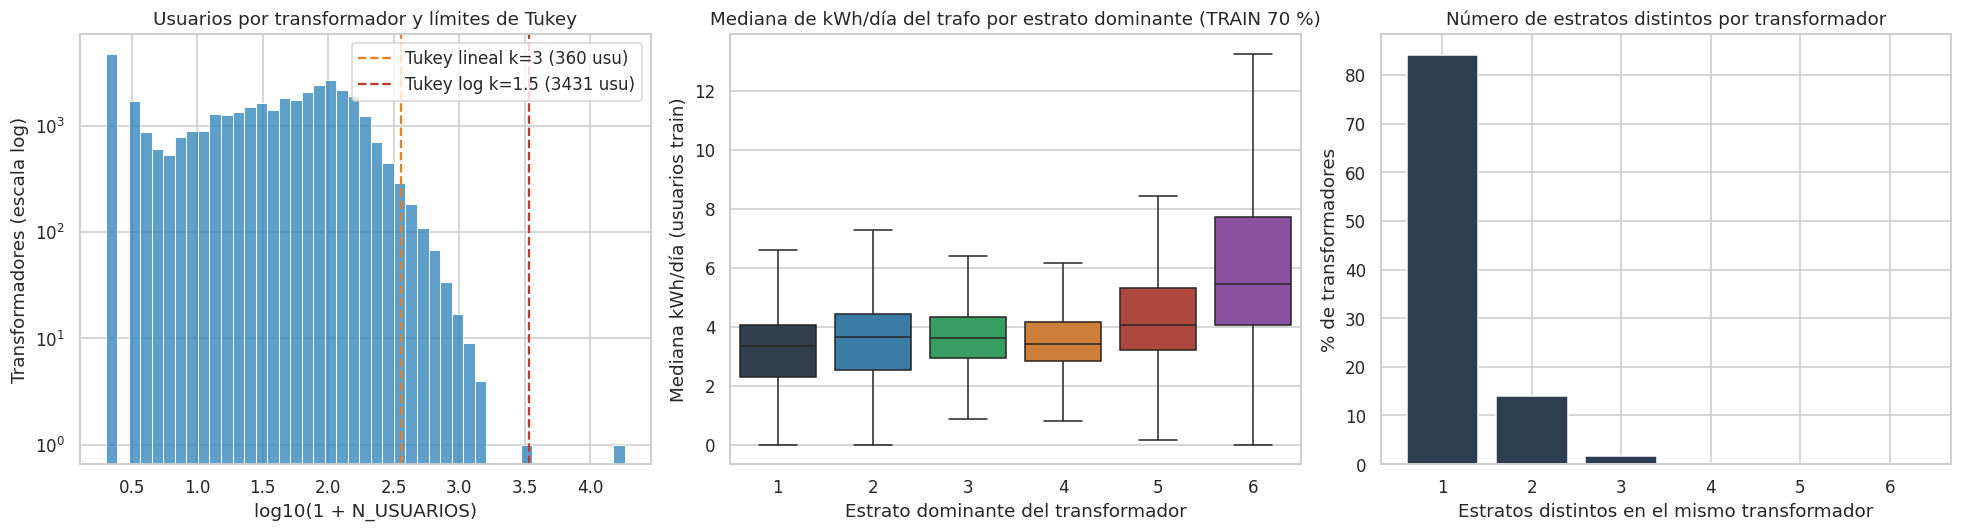

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribución de log10(1 + N_USUARIOS) y límites de Tukey
log_n_usu = np.log10(1.0 + df_trafo_estratos['N_USUARIOS'])
sns.histplot(log_n_usu, bins=45, color=PALETA[1], ax=axes[0])
axes[0].axvline(np.log10(1.0 + UMBRAL_USU_TUKEY_LIN), color=PALETA[3], linestyle='--',
                label=f'Tukey lineal k=3 ({UMBRAL_USU_TUKEY_LIN:.0f} usu)')
axes[0].axvline(np.log10(1.0 + UMBRAL_USU_TUKEY_LOG), color=PALETA[4], linestyle='--',
                label=f'Tukey log k=1.5 ({UMBRAL_USU_TUKEY_LOG:.0f} usu)')
axes[0].set_yscale('log')
axes[0].set_title('Usuarios por transformador y límites de Tukey')
axes[0].set_xlabel('log10(1 + N_USUARIOS)')
axes[0].set_ylabel('Transformadores (escala log)')
axes[0].legend()

# 2. Consumo diario mediano del transformador según su estrato dominante (en TRAIN 70 %)
sns.boxplot(
    data=df_trafo_estratos,
    x='ESTRATO_DOMINANTE',
    y='KWH_DIA_MEDIANA_USU',
    hue='ESTRATO_DOMINANTE',
    palette=PALETA,
    legend=False,
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title('Mediana de kWh/día del trafo por estrato dominante (TRAIN 70 %)')
axes[1].set_xlabel('Estrato dominante del transformador')
axes[1].set_ylabel('Mediana kWh/día (usuarios train)')

# 3. Pureza de estrato en los transformadores
conteo_n_est = df_trafo_estratos['N_ESTRATOS_DISTINTOS'].value_counts().sort_index()
axes[2].bar(conteo_n_est.index.astype(str), conteo_n_est.values / len(df_trafo_estratos) * 100, color=PALETA[0])
axes[2].set_title('Número de estratos distintos por transformador')
axes[2].set_xlabel('Estratos distintos en el mismo transformador')
axes[2].set_ylabel('% de transformadores')

plt.tight_layout()
guardar_figura(fig, '01_perfil_transformadores_y_tukey')
plt.show()

## 4. Caracterización de `COD_CIRCUITO_LINEA` (`df_circuitos`) y línea base de tamaño del efecto ($arepsilon^2$ y $\eta^2$)

1. Construimos `df_circuitos` para todos los códigos de circuito/línea de `2022–2025`, calculando las métricas de consumo diario **exclusivamente sobre el 70 % de entrenamiento** (`ES_TRAIN_70 == 1`) y agregando variables continuas de composición socioeconómica (`ESTRATO_PROMEDIO` y `ENTROPIA_ESTRATO`).
2. Medimos el tamaño del efecto real ($\eta^2$ ANOVA y $arepsilon^2$ de Kruskal–Wallis, brutos y ajustados por grados de libertad) sobre el conjunto de entrenamiento.

In [15]:
# 4.1 Construcción de df_circuitos (estructura en 100 % de datos, consumo en 70 % TRAIN)
usuarios_trafo['COD_CIRCUITO_CLEAN'] = (
    usuarios_trafo['COD_CIRCUITO_LINEA'].astype(str).str.strip().replace({'': 'SIN_CIRCUITO'})
)
df_trafo_estratos['COD_CIRCUITO_CLEAN'] = (
    df_trafo_estratos['COD_CIRCUITO_LINEA'].astype(str).str.strip().replace({'': 'SIN_CIRCUITO'})
)

g_circ_all = usuarios_trafo.groupby('COD_CIRCUITO_CLEAN')
df_circuitos_estructura = g_circ_all.agg(
    N_TRANSFORMADORES=('COD_TRANSFORMADOR', 'nunique'),
    N_USUARIOS=('NIU_USUARIO', 'count'),
    N_REGISTROS=('N_MESES_USUARIO', 'sum'),
)

usuarios_train = usuarios_trafo.loc[usuarios_trafo['ES_TRAIN_70'] == 1]
g_circ_train = usuarios_train.groupby('COD_CIRCUITO_CLEAN')

df_circuitos_train = g_circ_train.agg(
    N_USUARIOS_TRAIN=('NIU_USUARIO', 'count'),
    N_REGISTROS_TRAIN=('N_MESES_USUARIO', 'sum'),
    KWH_DIA_MEDIA_USU=('KWH_DIA_USUARIO_MEDIA', 'mean'),
    KWH_DIA_MEDIANA_USU=('KWH_DIA_USUARIO_MEDIA', 'median'),
    KWH_DIA_STD_USU=('KWH_DIA_USUARIO_MEDIA', 'std'),
    SUMA_KWH_DIA_CIRC=('SUMA_KWH_DIA', 'sum'),
    TOTAL_CEROS=('N_CEROS_USUARIO', 'sum'),
)
df_circuitos_train['KWH_DIA_Q1_USU'] = g_circ_train['KWH_DIA_USUARIO_MEDIA'].quantile(0.25)
df_circuitos_train['KWH_DIA_Q3_USU'] = g_circ_train['KWH_DIA_USUARIO_MEDIA'].quantile(0.75)
df_circuitos_train['KWH_DIA_IQR_USU'] = df_circuitos_train['KWH_DIA_Q3_USU'] - df_circuitos_train['KWH_DIA_Q1_USU']

df_circuitos_base = df_circuitos_estructura.join(df_circuitos_train, how='left')
df_circuitos_base['N_USUARIOS_TRAIN'] = df_circuitos_base['N_USUARIOS_TRAIN'].fillna(0).astype('int32')
df_circuitos_base['N_REGISTROS_TRAIN'] = df_circuitos_base['N_REGISTROS_TRAIN'].fillna(0).astype('int32')
df_circuitos_base['TOTAL_CEROS'] = df_circuitos_base['TOTAL_CEROS'].fillna(0).astype('int32')
df_circuitos_base['KWH_DIA_STD_USU'] = df_circuitos_base['KWH_DIA_STD_USU'].fillna(0.0)
df_circuitos_base['KWH_DIA_TOTAL_CIRC'] = df_circuitos_base['KWH_DIA_MEDIA_USU'] * df_circuitos_base['N_USUARIOS']
df_circuitos_base['PCT_CEROS'] = (
    df_circuitos_base['TOTAL_CEROS'] / df_circuitos_base['N_REGISTROS_TRAIN'].replace(0, np.nan)
) * 100.0

# Dispersión entre las medianas de los transformadores que pertenecen al mismo circuito (solo con N_USUARIOS_TRAIN >= 1)
trafos_con_train = df_trafo_estratos.loc[df_trafo_estratos['N_USUARIOS_TRAIN'] >= 1]
g_trafo_en_circ = trafos_con_train.groupby('COD_CIRCUITO_CLEAN')['KWH_DIA_MEDIANA_USU']
df_circuitos_base['STD_MEDIANA_TRAFOS'] = g_trafo_en_circ.std().reindex(df_circuitos_base.index).fillna(0.0)
df_circuitos_base['IQR_MEDIANA_TRAFOS'] = (
    (g_trafo_en_circ.quantile(0.75) - g_trafo_en_circ.quantile(0.25)).reindex(df_circuitos_base.index).fillna(0.0)
)
df_circuitos_base['N_TRAFOS_CON_MEDIANA'] = g_trafo_en_circ.count().reindex(df_circuitos_base.index).fillna(0).astype('int32')

# Composición por estrato (1..6) dentro de cada circuito
conteo_est_circ = (
    usuarios_trafo.groupby(['COD_CIRCUITO_CLEAN', 'ESTRATO_SECTOR'])['NIU_USUARIO']
    .count()
    .unstack(fill_value=0)
    .reindex(columns=ESTRATOS, fill_value=0)
)
conteo_est_circ.columns = [f'CANT_ESTRATO_{e}' for e in ESTRATOS]

pct_est_circ = conteo_est_circ.div(conteo_est_circ.sum(axis=1), axis=0) * 100.0
pct_est_circ.columns = [f'PCT_ESTRATO_{e}' for e in ESTRATOS]

estrato_dom_circ = conteo_est_circ.values.argmax(axis=1) + 1
pesos_circ = pct_est_circ.to_numpy(dtype='float64') / 100.0
estrato_prom_circ = (pesos_circ * np.array(ESTRATOS, dtype='float64')).sum(axis=1)
pureza_circ = pct_est_circ.max(axis=1)
n_estratos_circ = (conteo_est_circ > 0).sum(axis=1)

with np.errstate(divide='ignore', invalid='ignore'):
    entropia_circ = -np.nansum(np.where(pesos_circ > 0, pesos_circ * np.log(pesos_circ), 0.0), axis=1) / np.log(len(ESTRATOS))

df_circuitos = (
    df_circuitos_base
    .join(conteo_est_circ)
    .join(pct_est_circ)
    .assign(
        ESTRATO_DOMINANTE=pd.Series(estrato_dom_circ, index=conteo_est_circ.index, dtype='int8'),
        ESTRATO_PROMEDIO=pd.Series(estrato_prom_circ, index=conteo_est_circ.index, dtype='float64'),
        PUREZA_ESTRATO_PCT=pureza_circ,
        ENTROPIA_ESTRATO=pd.Series(entropia_circ, index=conteo_est_circ.index, dtype='float64'),
        N_ESTRATOS_DISTINTOS=n_estratos_circ.astype('int8')
    )
    .sort_values('N_USUARIOS', ascending=False)
)

print(f'df_circuitos: {df_circuitos.shape[0]:,} circuitos x {df_circuitos.shape[1]} columnas')
df_circuitos.head(10)

df_circuitos: 1,063 circuitos x 35 columnas


,N_TRANSFORMADORES,N_USUARIOS,N_REGISTROS,N_USUARIOS_TRAIN,N_REGISTROS_TRAIN,KWH_DIA_MEDIA_USU,KWH_DIA_MEDIANA_USU,KWH_DIA_STD_USU,SUMA_KWH_DIA_CIRC,TOTAL_CEROS,...,PCT_ESTRATO_2,PCT_ESTRATO_3,PCT_ESTRATO_4,PCT_ESTRATO_5,PCT_ESTRATO_6,ESTRATO_DOMINANTE,ESTRATO_PROMEDIO,PUREZA_ESTRATO_PCT,ENTROPIA_ESTRATO,N_ESTRATOS_DISTINTOS
COD_CIRCUITO_CLEAN,,,,,,,,,,,,,,,,,,,,,
SIN_CIRCUITO,18290,426721,15743235,298472,11007426,3.5478,2.9297,3.2960,"42,956,082.2380",432038,...,28.9229,38.6953,19.6229,5.2531,3.0413,3,3.0140,38.6953,0.8068,6
0550,60,16717,222118,11625,154336,2.2981,1.1429,3.3470,"606,671.5816",6039,...,44.5774,26.0394,24.2508,2.2971,1.5792,2,2.8649,44.5774,0.7039,6
0302,65,14159,635041,9823,440520,3.1544,2.8268,2.4976,"1,389,723.0157",12780,...,83.9890,0.0353,0.0000,0.0000,0.0000,2,1.8406,83.9890,0.2469,3
0305,69,13615,645517,9589,454437,3.2714,2.7976,2.4445,"1,477,491.1012",18192,...,95.3434,2.1814,0.0000,0.0073,0.0000,2,1.9974,95.3434,0.1233,4
0255,168,13142,610084,9146,424934,4.0670,3.4263,3.0652,"1,743,709.9195",9756,...,31.4107,36.2806,0.0913,0.0000,0.0000,3,2.0425,36.2806,0.6155,4
1223,86,11821,551825,8232,384006,3.7673,3.2819,2.7704,"1,455,285.3784",15200,...,1.9034,0.2115,0.0000,0.1100,0.0846,1,1.0319,97.6906,0.0696,5
0315,80,11815,549046,8296,385155,3.3034,2.7905,2.5887,"1,269,732.9547",12144,...,31.1384,0.1185,0.0000,0.0000,0.0000,1,1.3138,68.7431,0.3510,3
0312,74,11732,559687,8231,392586,3.8445,3.3979,2.7001,"1,505,880.1916",6220,...,99.9574,0.0170,0.0000,0.0000,0.0085,2,2.0003,99.9574,0.0023,4
0313,79,11508,538816,7963,373018,3.8602,3.2574,2.9748,"1,440,823.7235",8604,...,48.2186,0.0521,0.0000,0.0000,0.0000,1,1.4832,51.7292,0.3888,3


In [16]:
# 4.2 Cálculo vectorizado de Tamaño del Efecto (Eta^2 ANOVA y Epsilon^2 de Kruskal-Wallis)
# Se provee evaluación tanto en TRAIN (70 %, para toma de decisiones e hiperparámetros) como en VAL+TEST (30 %, para verificar generalización fuera de muestra)
def construir_evaluador_efecto(df_eval):
    y_val = df_eval['KWH_DIA_USUARIO_MEDIA'].to_numpy(dtype='float64')
    y_log = np.log1p(np.clip(y_val, 0.0, None))
    y_rank = df_eval['KWH_DIA_USUARIO_MEDIA'].rank(method='average').to_numpy(dtype='float64')

    N_tot = len(df_eval)
    ss_tot_val = ((y_val - y_val.mean()) ** 2).sum()
    ss_tot_log = ((y_log - y_log.mean()) ** 2).sum()
    mean_rank_global = (N_tot + 1.0) / 2.0

    def _evaluar(col_grupo, nombre_nivel):
        g = df_eval.groupby(col_grupo, observed=True)
        n_j = g['KWH_DIA_USUARIO_MEDIA'].count().to_numpy(dtype='float64')
        k = len(n_j)

        mean_j_val = g['KWH_DIA_USUARIO_MEDIA'].mean().to_numpy(dtype='float64')
        ss_btw_val = (n_j * ((mean_j_val - y_val.mean()) ** 2)).sum()
        eta2_val = ss_btw_val / ss_tot_val
        eta2_adj_val = 1.0 - (1.0 - eta2_val) * (N_tot - 1.0) / max(N_tot - k, 1.0)

        mean_j_log = df_eval.assign(_ylog=y_log).groupby(col_grupo, observed=True)['_ylog'].mean().to_numpy(dtype='float64')
        ss_btw_log = (n_j * ((mean_j_log - y_log.mean()) ** 2)).sum()
        eta2_log = ss_btw_log / ss_tot_log
        eta2_adj_log = 1.0 - (1.0 - eta2_log) * (N_tot - 1.0) / max(N_tot - k, 1.0)

        mean_j_rank = df_eval.assign(_yrank=y_rank).groupby(col_grupo, observed=True)['_yrank'].mean().to_numpy(dtype='float64')
        H_kw = (12.0 / (N_tot * (N_tot + 1.0))) * (n_j * ((mean_j_rank - mean_rank_global) ** 2)).sum()
        eps2_kw = H_kw / (N_tot - 1.0)
        eps2_adj_kw = (H_kw - k + 1.0) / max(N_tot - k, 1.0)

        return {
            'Nivel / Variable': nombre_nivel,
            'Cardinalidad (k)': k,
            'Eta2_KWH_DIA (%)': eta2_val * 100,
            'Eta2_Adj_KWH_DIA (%)': eta2_adj_val * 100,
            'Eta2_log1p (%)': eta2_log * 100,
            'Eta2_Adj_log1p (%)': eta2_adj_log * 100,
            'Epsilon2_KW (%)': eps2_kw * 100,
            'Epsilon2_Adj_KW (%)': eps2_adj_kw * 100,
        }
    return _evaluar

usuarios_trafo['CIRCUITO_X_ESTRATO'] = (
    usuarios_trafo['COD_CIRCUITO_CLEAN'].astype(str) + '_E' + usuarios_trafo['ESTRATO_SECTOR'].astype(str)
)

usuarios_train = usuarios_trafo.loc[usuarios_trafo['ES_TRAIN_70'] == 1].copy()
usuarios_holdout = usuarios_trafo.loc[usuarios_trafo['ES_TRAIN_70'] == 0].copy()

eval_train = construir_evaluador_efecto(usuarios_train)
eval_holdout = construir_evaluador_efecto(usuarios_holdout)

resultados_efectos = pd.DataFrame([
    eval_train('ESTRATO_SECTOR', '1. ESTRATO_SECTOR'),
    eval_train('COD_CIRCUITO_CLEAN', '2. COD_CIRCUITO_LINEA'),
    eval_train('CIRCUITO_X_ESTRATO', '3. CIRCUITO x ESTRATO'),
    eval_train('COD_TRANSFORMADOR', '4. COD_TRANSFORMADOR'),
]).set_index('Nivel / Variable')

resultados_efectos

,Cardinalidad (k),Eta2_KWH_DIA (%),Eta2_Adj_KWH_DIA (%),Eta2_log1p (%),Eta2_Adj_log1p (%),Epsilon2_KW (%),Epsilon2_Adj_KW (%)
Nivel / Variable,,,,,,,
1. ESTRATO_SECTOR,6,2.1442,2.1439,1.9857,1.9854,1.8721,1.8718
2. COD_CIRCUITO_LINEA,1043,5.1931,5.1362,7.5480,7.4925,7.0263,6.9704
3. CIRCUITO x ESTRATO,2828,7.4747,7.3237,10.2866,10.1402,9.5700,9.4224
4. COD_TRANSFORMADOR,35699,17.9130,16.1883,23.9195,22.3209,22.7648,21.1419


## 5. Preprocesamiento estadístico, pruebas de asimetría y *clustering* independiente

### 5.1 Imputación del estrato para unidades con $N_{	ext{train}} \le 2$ y suavizamiento empírico (*Empirical Bayes*)
1. **Imputación por estrato cuando $N_{	ext{train}} = 0$ o $N_{	ext{train}} \le 2$:**
   - Si una unidad no tiene lecturas en el 70 % de entrenamiento ($N_{	ext{train}} = 0$), su mediana, $\mathrm{IQR}$ y `% de ceros` se imputan directamente con la mediana de su `ESTRATO_DOMINANTE`.
   - Para el rango intercuartílico entre usuarios (`KWH_DIA_IQR_USU`), cuando $N_{	ext{train}} \le 2$ (`N_MIN_IQR = 3`), el $\mathrm{IQR}$ muestral es degenerado ($\mathrm{IQR} = 0$ para $N=1$), lo que antes producía un clúster artificial de transformadores monopunto (`T05`). Con la regla de grados de libertad efectivos $N_{	ext{ef}} = \max(0,\; N_{	ext{train}} - 2)$, toda unidad con $N_{	ext{train}} \le 2$ recibe peso $w_{	ext{iqr}} = 0$ y **se le imputa directamente el $\mathrm{IQR}$ mediano de su `ESTRATO_DOMINANTE`**:
     $$w_{	ext{med}, i} = rac{N_{	ext{train}, i}}{N_{	ext{train}, i} + m}, \qquad w_{	ext{iqr}, i} = rac{\max(0,\; N_{	ext{train}, i} - 2)}{\max(0,\; N_{	ext{train}, i} - 2) + m}$$
2. **Desacoplamiento del estrato (residuo intra-estrato):**
   - Se calcula `RESIDUAL_ESTRATO_KWH` $= 	ext{KWH\_DIA\_MEDIANA\_SMOOTH} - \mu_{	ext{mediana, estrato}}$, que mide en cuántos kWh/día supera o queda por debajo cada transformador respecto a la norma de su estrato.

In [17]:
# 5.1 Cálculo de priors por ESTRATO_DOMINANTE (usando solo unidades con muestra válida en TRAIN 70 %)
trafos_base_prior = df_trafo_estratos.loc[df_trafo_estratos['N_USUARIOS_TRAIN'] >= N_MIN_IQR]
prior_trafo_mediana = df_trafo_estratos.loc[df_trafo_estratos['N_USUARIOS_TRAIN'] >= 1].groupby('ESTRATO_DOMINANTE')['KWH_DIA_MEDIANA_USU'].median()
prior_trafo_iqr = trafos_base_prior.groupby('ESTRATO_DOMINANTE')['KWH_DIA_IQR_USU'].median()
prior_trafo_ceros = df_trafo_estratos.loc[df_trafo_estratos['N_USUARIOS_TRAIN'] >= 1].groupby('ESTRATO_DOMINANTE')['PCT_CEROS'].median()

circs_base_prior = df_circuitos.loc[(df_circuitos.index != 'SIN_CIRCUITO') & (df_circuitos['N_USUARIOS_TRAIN'] >= N_MIN_IQR)]
prior_circ_mediana = df_circuitos.loc[df_circuitos['N_USUARIOS_TRAIN'] >= 1].groupby('ESTRATO_DOMINANTE')['KWH_DIA_MEDIANA_USU'].median()
prior_circ_iqr = circs_base_prior.groupby('ESTRATO_DOMINANTE')['KWH_DIA_IQR_USU'].median()
prior_circ_iqr_trafos = df_circuitos.loc[df_circuitos['N_TRAFOS_CON_MEDIANA'] >= N_MIN_IQR].groupby('ESTRATO_DOMINANTE')['IQR_MEDIANA_TRAFOS'].median()
prior_circ_ceros = df_circuitos.loc[df_circuitos['N_USUARIOS_TRAIN'] >= 1].groupby('ESTRATO_DOMINANTE')['PCT_CEROS'].median()

# --- Suavizamiento e imputación por estrato en Transformadores (m = 15) ---
n_tr_t = df_trafo_estratos['N_USUARIOS_TRAIN'].to_numpy(dtype='float64')
w_med_t = n_tr_t / (n_tr_t + M_SMOOTH_TRAFO)
n_ef_iqr_t = np.maximum(0.0, n_tr_t - (N_MIN_IQR - 1.0))  # 0 cuando N_train <= 2 -> imputa 100 % el estrato
w_iqr_t = n_ef_iqr_t / (n_ef_iqr_t + M_SMOOTH_TRAFO)

med_prior_t = df_trafo_estratos['ESTRATO_DOMINANTE'].map(prior_trafo_mediana).to_numpy(dtype='float64')
iqr_prior_t = df_trafo_estratos['ESTRATO_DOMINANTE'].map(prior_trafo_iqr).to_numpy(dtype='float64')
ceros_prior_t = df_trafo_estratos['ESTRATO_DOMINANTE'].map(prior_trafo_ceros).to_numpy(dtype='float64')

med_obs_t = df_trafo_estratos['KWH_DIA_MEDIANA_USU'].fillna(pd.Series(med_prior_t, index=df_trafo_estratos.index)).to_numpy(dtype='float64')
iqr_obs_t = df_trafo_estratos['KWH_DIA_IQR_USU'].fillna(pd.Series(iqr_prior_t, index=df_trafo_estratos.index)).to_numpy(dtype='float64')
ceros_obs_t = df_trafo_estratos['PCT_CEROS'].fillna(pd.Series(ceros_prior_t, index=df_trafo_estratos.index)).to_numpy(dtype='float64')

df_trafo_estratos['KWH_DIA_MEDIANA_SMOOTH'] = w_med_t * med_obs_t + (1.0 - w_med_t) * med_prior_t
df_trafo_estratos['KWH_DIA_IQR_SMOOTH'] = w_iqr_t * iqr_obs_t + (1.0 - w_iqr_t) * iqr_prior_t
df_trafo_estratos['PCT_CEROS_SMOOTH'] = w_med_t * ceros_obs_t + (1.0 - w_med_t) * ceros_prior_t

# Residuo intra-estrato (desacopla el nivel del transformador respecto a su estrato dominante)
df_trafo_estratos['RESIDUAL_ESTRATO_KWH'] = df_trafo_estratos['KWH_DIA_MEDIANA_SMOOTH'] - med_prior_t
df_trafo_estratos['Z_INTRA_ESTRATO_KWH'] = df_trafo_estratos['RESIDUAL_ESTRATO_KWH'] / iqr_prior_t
df_trafo_estratos['LOG_N_USUARIOS'] = np.log10(1.0 + df_trafo_estratos['N_USUARIOS'])

# --- Suavizamiento e imputación por estrato en Circuitos (m = 30) ---
n_tr_c = df_circuitos['N_USUARIOS_TRAIN'].to_numpy(dtype='float64')
w_med_c = n_tr_c / (n_tr_c + M_SMOOTH_CIRC)
n_ef_iqr_c = np.maximum(0.0, n_tr_c - (N_MIN_IQR - 1.0))
w_iqr_c = n_ef_iqr_c / (n_ef_iqr_c + M_SMOOTH_CIRC)

n_tr_trafos_c = np.maximum(0.0, df_circuitos['N_TRAFOS_CON_MEDIANA'].to_numpy(dtype='float64') - (N_MIN_IQR - 1.0))
w_iqr_trafos_c = n_tr_trafos_c / (n_tr_trafos_c + 10.0)

med_prior_c = df_circuitos['ESTRATO_DOMINANTE'].map(prior_circ_mediana).to_numpy(dtype='float64')
iqr_prior_c = df_circuitos['ESTRATO_DOMINANTE'].map(prior_circ_iqr).to_numpy(dtype='float64')
iqr_tr_prior_c = df_circuitos['ESTRATO_DOMINANTE'].map(prior_circ_iqr_trafos).to_numpy(dtype='float64')
ceros_prior_c = df_circuitos['ESTRATO_DOMINANTE'].map(prior_circ_ceros).to_numpy(dtype='float64')

med_obs_c = df_circuitos['KWH_DIA_MEDIANA_USU'].fillna(pd.Series(med_prior_c, index=df_circuitos.index)).to_numpy(dtype='float64')
iqr_obs_c = df_circuitos['KWH_DIA_IQR_USU'].fillna(pd.Series(iqr_prior_c, index=df_circuitos.index)).to_numpy(dtype='float64')
iqr_tr_obs_c = df_circuitos['IQR_MEDIANA_TRAFOS'].fillna(pd.Series(iqr_tr_prior_c, index=df_circuitos.index)).to_numpy(dtype='float64')
ceros_obs_c = df_circuitos['PCT_CEROS'].fillna(pd.Series(ceros_prior_c, index=df_circuitos.index)).to_numpy(dtype='float64')

df_circuitos['KWH_DIA_MEDIANA_SMOOTH'] = w_med_c * med_obs_c + (1.0 - w_med_c) * med_prior_c
df_circuitos['KWH_DIA_IQR_SMOOTH'] = w_iqr_c * iqr_obs_c + (1.0 - w_iqr_c) * iqr_prior_c
df_circuitos['IQR_MEDIANA_TRAFOS_SMOOTH'] = w_iqr_trafos_c * iqr_tr_obs_c + (1.0 - w_iqr_trafos_c) * iqr_tr_prior_c
df_circuitos['PCT_CEROS_SMOOTH'] = w_med_c * ceros_obs_c + (1.0 - w_med_c) * ceros_prior_c
df_circuitos['RESIDUAL_ESTRATO_KWH'] = df_circuitos['KWH_DIA_MEDIANA_SMOOTH'] - med_prior_c
df_circuitos['LOG_N_TRANSFORMADORES'] = np.log10(1.0 + df_circuitos['N_TRANSFORMADORES'])
df_circuitos['LOG_N_USUARIOS'] = np.log10(1.0 + df_circuitos['N_USUARIOS'])

print(f"Transformadores con N_train <= 2 imputados con IQR de su estrato: {(n_tr_t <= 2).sum():,} ({(n_tr_t <= 2).mean()*100:.2f} %)")
print(f"Mínimo KWH_DIA_IQR_SMOOTH en transformadores tras imputación: {df_trafo_estratos['KWH_DIA_IQR_SMOOTH'].min():.4f} kWh/día")

Transformadores con N_train <= 2 imputados con IQR de su estrato: 7,328 (19.62 %)
Mínimo KWH_DIA_IQR_SMOOTH en transformadores tras imputación: 0.2119 kWh/día


### 5.2 Justificación estadística de las transformaciones logarítmicas antes de `RobustScaler`

**Fundamento matemático:**
- `RobustScaler` aplica la transformación lineal $z_{	ext{rob}} = rac{x - Q_2}{Q_3 - Q_1}$, la cual **preserva exactamente el coeficiente de asimetría de Fisher–Pearson ($g_1$)** y la asimetría intercuartílica de Bowley ($S_B$).
- En `KMeans`, la función objetivo minimiza la suma de distancias euclidianas al cuadrado $\sum \| \mathbf{z}_i - oldsymbol{\mu}_k \|_2^2$. Si una variable presenta asimetría positiva fuerte ($g_1 > 1,0$), las observaciones en la cola derecha alcanzan valores de $|z_{	ext{rob}}| > 15	ext{–}25\;\mathrm{IQR}$, aportando un peso cuadrático ($z_{	ext{rob}}^2 > 225	ext{–}625$) que domina la inercia y fuerza a `KMeans` a dedicar clústeres enteros a unos pocos registros extremos.
- **Criterio de decisión automático:** se evalúa cada variable candidata en escala original y en escala $\log(1 + x)$; la función `aplicar_transformaciones_verificadas` adopta $\log(1 + x)$ si y solo si $|g_1| > 1,0$ en escala original y la transformación reduce simultáneamente $|g_1|$ y el apalancamiento cuadrático máximo $\max z_{	ext{rob}}^2$.

In [18]:
# Diagnóstico de asimetría y apalancamiento cuadrático en Transformadores y Circuitos
candidatas_asimetria_trafo = ['N_USUARIOS', 'KWH_DIA_MEDIANA_SMOOTH', 'KWH_DIA_IQR_SMOOTH', 'PCT_CEROS_SMOOTH']
tabla_asim_trafo = diagnostico_asimetria_y_apalancamiento(df_trafo_estratos, candidatas_asimetria_trafo)
print('=== Diagnóstico de asimetría y apalancamiento cuadrático: Transformadores ===')
display(tabla_asim_trafo)

df_circ_sin_vacio = df_circuitos.loc[df_circuitos.index != 'SIN_CIRCUITO']
candidatas_asimetria_circ = [
    'N_TRANSFORMADORES', 'N_USUARIOS', 'KWH_DIA_MEDIANA_SMOOTH',
    'KWH_DIA_IQR_SMOOTH', 'IQR_MEDIANA_TRAFOS_SMOOTH', 'PCT_CEROS_SMOOTH'
]
tabla_asim_circ = diagnostico_asimetria_y_apalancamiento(df_circ_sin_vacio, candidatas_asimetria_circ)
print('\n=== Diagnóstico de asimetría y apalancamiento cuadrático: Circuitos ===')
display(tabla_asim_circ)

=== Diagnóstico de asimetría y apalancamiento cuadrático: Transformadores ===


,g1_original,Bowley_original,max_|z_rob|_original,max_z2_original,g1_log1p,Bowley_log1p,max_|z_rob|_log1p,max_z2_log1p,Transformar_log1p
Variable,,,,,,,,,
N_USUARIOS,75.7900,0.3409,206.9205,"42,816.0745",-0.3756,-0.2117,2.5969,6.7441,True
KWH_DIA_MEDIANA_SMOOTH,1.6786,0.2978,10.4307,108.7992,0.1216,0.2526,7.4127,54.9487,True
KWH_DIA_IQR_SMOOTH,1.3742,-0.0245,10.8698,118.1522,0.2553,-0.0928,5.0050,25.0500,True
PCT_CEROS_SMOOTH,6.2282,0.2238,36.9264,"1,363.5593",1.1379,0.0825,5.4395,29.5886,True



=== Diagnóstico de asimetría y apalancamiento cuadrático: Circuitos ===


,g1_original,Bowley_original,max_|z_rob|_original,max_z2_original,g1_log1p,Bowley_log1p,max_|z_rob|_log1p,max_z2_log1p,Transformar_log1p
Variable,,,,,,,,,
N_TRANSFORMADORES,1.9821,0.3750,5.6875,32.3477,-0.1969,-0.1403,1.2011,1.4426,True
N_USUARIOS,1.6262,0.6938,4.9957,24.9569,-0.2909,-0.2897,1.0674,1.1394,True
KWH_DIA_MEDIANA_SMOOTH,0.7850,0.0829,5.5433,30.7278,-0.7388,0.0271,5.1684,26.7123,False
KWH_DIA_IQR_SMOOTH,1.8004,0.1191,9.6287,92.7115,0.3109,0.0758,5.6792,32.2529,True
IQR_MEDIANA_TRAFOS_SMOOTH,3.0976,-0.0377,10.0342,100.6859,1.4215,-0.0998,4.9910,24.9104,True
PCT_CEROS_SMOOTH,3.2963,0.3504,13.4428,180.7096,1.2388,0.2506,4.5417,20.6270,True


In [19]:
# Aplicación programática de las transformaciones log(1 + x) según el resultado de la prueba estadística
mapeo_transf_trafo = {
    'KWH_DIA_MEDIANA_SMOOTH': 'LOG_KWH_DIA_MEDIANA_SMOOTH',
    'KWH_DIA_IQR_SMOOTH': 'LOG_KWH_DIA_IQR_SMOOTH',
    'PCT_CEROS_SMOOTH': 'LOG_PCT_CEROS_SMOOTH',
}
aplicar_transformaciones_verificadas(df_trafo_estratos, tabla_asim_trafo, mapeo_transf_trafo)

mapeo_transf_circ = {
    'KWH_DIA_MEDIANA_SMOOTH': 'LOG_KWH_DIA_MEDIANA_SMOOTH',
    'KWH_DIA_IQR_SMOOTH': 'LOG_KWH_DIA_IQR_SMOOTH',
    'IQR_MEDIANA_TRAFOS_SMOOTH': 'LOG_IQR_MEDIANA_TRAFOS_SMOOTH',
    'PCT_CEROS_SMOOTH': 'LOG_PCT_CEROS_SMOOTH',
}
aplicar_transformaciones_verificadas(df_circuitos, tabla_asim_circ, mapeo_transf_circ)

### 5.3 Tratamiento estadístico de atípicos multivariados en el ajuste de `KMeans` (criterio de Tukey)

Para evitar que unidades con valores atípicos en cualquiera de las características de clustering distorsionen la ubicación de los centróides —sin recurrir a cortes arbitrarios ni excluir códigos del catálogo— se aplica el siguiente procedimiento:
1. Para cada característica $j$ de la matriz de clustering (ya simetrizada), se calculan sus cuartiles exactos $Q_{1,j}, Q_{3,j}$ e $\mathrm{IQR}_j = Q_{3,j} - Q_{1,j}$.
2. Una unidad $i$ se identifica como **atípica en el espacio de clustering** si supera los límites de Tukey $[Q_{1,j} - k\,\mathrm{IQR}_j,\; Q_{3,j} + k\,\mathrm{IQR}_j]$ en alguna dimensión.
3. El escalador `RobustScaler` y el modelo `KMeans` se entrenan (`fit`) **únicamente sobre las unidades no atípicas (*inliers*)**.
4. Para asignar clúster al **100 % de las unidades**, las coordenadas de las unidades atípicas se acotan (winsorizan) al intervalo de Tukey $[Q_{1,j} - k\,\mathrm{IQR}_j,\; Q_{3,j} + k\,\mathrm{IQR}_j]$ antes de evaluar `km.predict()`, y se registra la columna indicadora de atipicidad en el catálogo.
5. Se evalúa la sensibilidad del tamaño del efecto retenido ($\eta^2_{	ext{adj}}$ y $arepsilon^2_{	ext{adj}}$) para $k \in \{1,5;\; 2,0;\; 3,0\}$.

In [20]:
def preparar_espacio_tukey(df_unidades, cols_features, k_tukey):
    """
    Identifica inliers según los límites de Tukey [Q1 - k*IQR, Q3 + k*IQR] en cada característica,
    ajusta RobustScaler sobre los inliers y devuelve:
    - X_inliers: matriz escalada solo de unidades no atípicas (para ajustar centróides de KMeans)
    - X_all_acotado: matriz escalada de TODAS las unidades (con valores extremos acotados al límite de Tukey para asignación .predict())
    - mask_atipico: serie booleana que identifica las unidades atípicas según Tukey
    - scaler: instancia de RobustScaler ajustada
    """
    mat_raw = df_unidades[cols_features].to_numpy(dtype='float64', copy=True)
    q1 = np.percentile(mat_raw, 25, axis=0)
    q3 = np.percentile(mat_raw, 75, axis=0)
    iqr = np.maximum(q3 - q1, 1e-9)

    lim_inf = q1 - k_tukey * iqr
    lim_sup = q3 + k_tukey * iqr

    fuera_matriz = (mat_raw < lim_inf) | (mat_raw > lim_sup)
    mask_atipico = pd.Series(fuera_matriz.any(axis=1), index=df_unidades.index)

    mat_acotada = np.clip(mat_raw, lim_inf, lim_sup)
    inliers_idx = ~mask_atipico.to_numpy()

    scaler = RobustScaler()
    scaler.fit(mat_raw[inliers_idx])

    X_inliers = scaler.transform(mat_raw[inliers_idx])
    X_all_acotado = scaler.transform(mat_acotada)
    return X_inliers, X_all_acotado, mask_atipico, scaler

### 5.4 Clustering 1 — `CLUSTER_CIRCUITO` (sobre `df_circuitos`)
- Se utilizan variables continuas de escala ($\log_{10}(1 + N_{	ext{trafos}})$, $\log_{10}(1 + N_{	ext{usuarios}})$), perfil energético suavizado (`LOG_KWH_DIA_MEDIANA_SMOOTH`, `RESIDUAL_ESTRATO_KWH`, `LOG_KWH_DIA_IQR_SMOOTH`, `LOG_IQR_MEDIANA_TRAFOS_SMOOTH`, `LOG_PCT_CEROS_SMOOTH`) y composición socioeconómica continua (`ESTRATO_PROMEDIO` y `ENTROPIA_ESTRATO`).
- Para los transformadores cuyo código de circuito en la fuente es vacío (`SIN_CIRCUITO`), en lugar de dejarlos en un único bloque plano indiferenciado que pierde variabilidad, se asignan a sub-clústeres de circuito según su estrato dominante (`C00_SIN_CIRC_E1` … `C00_SIN_CIRC_E6`), preservando la distinción física entre circuitos codificados y sin código.

In [21]:
features_circ = [
    'LOG_N_TRANSFORMADORES', 'LOG_N_USUARIOS',
    'LOG_KWH_DIA_MEDIANA_SMOOTH', 'RESIDUAL_ESTRATO_KWH',
    'LOG_KWH_DIA_IQR_SMOOTH', 'LOG_IQR_MEDIANA_TRAFOS_SMOOTH',
    'LOG_PCT_CEROS_SMOOTH', 'ESTRATO_PROMEDIO', 'ENTROPIA_ESTRATO'
]

df_circ_validos = df_circuitos.loc[df_circuitos.index != 'SIN_CIRCUITO'].copy()
eta2_ref_circ = resultados_efectos.loc['2. COD_CIRCUITO_LINEA', 'Eta2_Adj_KWH_DIA (%)']
eps2_ref_circ = resultados_efectos.loc['2. COD_CIRCUITO_LINEA', 'Epsilon2_Adj_KW (%)']

# 1. Sensibilidad al parámetro k de Tukey en Circuitos (fijando K = 8 clústeres base)
sens_tukey_circ = []
for k_tuk in K_TUKEY_CANDIDATOS:
    X_in_c, X_all_c, mask_at_c, _ = preparar_espacio_tukey(df_circ_validos, features_circ, k_tuk)
    km_c = KMeans(n_clusters=8, random_state=SEMILLA, n_init=20).fit(X_in_c)
    lbl_c = km_c.predict(X_all_c)
    tam_min = pd.Series(lbl_c).value_counts().min()

    mapa_c = pd.Series([f'C_{x}' for x in lbl_c], index=df_circ_validos.index).to_dict()
    col_c = np.where(
        usuarios_train['COD_CIRCUITO_CLEAN'] == 'SIN_CIRCUITO',
        'C00_E' + usuarios_train['ESTRATO_SECTOR'].astype(str),
        usuarios_train['COD_CIRCUITO_CLEAN'].map(mapa_c)
    )
    ef_c = eval_train(pd.Series(col_c, index=usuarios_train.index), f'Tukey k={k_tuk}')
    sens_tukey_circ.append({
        'k_Tukey': k_tuk,
        'Circuitos_Atipicos': int(mask_at_c.sum()),
        '%_Atipicos': mask_at_c.mean() * 100,
        'Min_Circuitos_en_Cluster': int(tam_min),
        'Silueta_Inliers': silhouette_score(X_in_c, km_c.labels_),
        'Eta2_Adj_TRAIN (%)': ef_c['Eta2_Adj_KWH_DIA (%)'],
        'Retencion_Eta2 (%)': ef_c['Eta2_Adj_KWH_DIA (%)'] / eta2_ref_circ * 100,
        'Epsilon2_Adj_TRAIN (%)': ef_c['Epsilon2_Adj_KW (%)'],
        'Retencion_Epsilon2 (%)': ef_c['Epsilon2_Adj_KW (%)'] / eps2_ref_circ * 100,
    })

pd.DataFrame(sens_tukey_circ).set_index('k_Tukey')

,Circuitos_Atipicos,%_Atipicos,Min_Circuitos_en_Cluster,Silueta_Inliers,Eta2_Adj_TRAIN (%),Retencion_Eta2 (%),Epsilon2_Adj_TRAIN (%),Retencion_Epsilon2 (%)
k_Tukey,,,,,,,,
1.5000,189,17.7966,95,0.1923,3.8163,74.3026,5.4222,77.7885
2.0000,100,9.4162,78,0.2016,3.6238,70.5551,5.2198,74.8855
3.0000,24,2.2599,59,0.2111,4.2820,83.3700,5.6590,81.1865


In [22]:
# 2. Evaluación de la grilla de K clústeres para COD_CIRCUITO_LINEA con k_Tukey = 2.0
K_TUKEY_CIRC = 2.0
X_in_circ, X_all_circ, mask_atip_circ, scaler_circ = preparar_espacio_tukey(df_circ_validos, features_circ, K_TUKEY_CIRC)
df_circ_validos['ES_CIRCUITO_ATIPICO'] = mask_atip_circ.astype('int8')

K_GRID_CIRC = [4, 5, 6, 8, 10, 12, 15, 20]
metricas_k_circ = []
modelos_circ = {}

for k in K_GRID_CIRC:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=20)
    km.fit(X_in_circ)
    labels = km.predict(X_all_circ)
    modelos_circ[k] = labels

    sil = silhouette_score(X_in_circ, km.labels_)
    ch = calinski_harabasz_score(X_in_circ, km.labels_)
    min_n = int(pd.Series(labels).value_counts().min())

    mapa_c = pd.Series([f'C{x}' for x in labels], index=df_circ_validos.index).to_dict()
    usuarios_train['_tmp_cl_circ'] = np.where(
        usuarios_train['COD_CIRCUITO_CLEAN'] == 'SIN_CIRCUITO',
        'C00_SIN_CIRC_E' + usuarios_train['ESTRATO_SECTOR'].astype(str),
        usuarios_train['COD_CIRCUITO_CLEAN'].map(mapa_c)
    )

    ef = eval_train('_tmp_cl_circ', f'K={k}')
    metricas_k_circ.append({
        'K_Circuitos': k,
        'Inercia_Inliers': km.inertia_,
        'Silueta_Inliers': sil,
        'Calinski_Harabasz': ch,
        'Min_Circuitos_Cluster': min_n,
        'Eta2_Adj_KWH_DIA (%)': ef['Eta2_Adj_KWH_DIA (%)'],
        'Retencion_Eta2 (%)': (ef['Eta2_Adj_KWH_DIA (%)'] / eta2_ref_circ) * 100,
        'Epsilon2_Adj_KW (%)': ef['Epsilon2_Adj_KW (%)'],
        'Retencion_Epsilon2 (%)': (ef['Epsilon2_Adj_KW (%)'] / eps2_ref_circ) * 100,
    })

usuarios_train.drop(columns=['_tmp_cl_circ'], inplace=True)
df_eval_k_circ = pd.DataFrame(metricas_k_circ).set_index('K_Circuitos')
df_eval_k_circ

,Inercia_Inliers,Silueta_Inliers,Calinski_Harabasz,Min_Circuitos_Cluster,Eta2_Adj_KWH_DIA (%),Retencion_Eta2 (%),Epsilon2_Adj_KW (%),Retencion_Epsilon2 (%)
K_Circuitos,,,,,,,,
4,"2,794.1022",0.2229,255.0681,235,2.8968,56.4010,4.6748,67.0659
5,"2,471.2931",0.2375,247.3154,162,3.4334,66.8483,5.1151,73.3825
6,"2,313.0759",0.2141,224.2431,119,3.6196,70.4731,5.1718,74.1970
8,"2,056.4670",0.2016,196.7894,78,3.6238,70.5551,5.2198,74.8855
10,"1,883.5414",0.2044,176.4715,65,3.7963,73.9133,5.3060,76.1211
12,"1,745.1737",0.1977,162.3535,58,4.2508,82.7624,5.8739,84.2688
15,"1,585.7095",0.1875,146.7508,46,4.4293,86.2382,6.1290,87.9291
20,"1,390.5224",0.1828,129.6189,36,4.4853,87.3277,6.2490,89.6505


In [34]:
# Asignación de CLUSTER_CIRCUITO (K = 8 clústeres físicos ordenados por consumo mediano + sub-clústeres para SIN_CIRCUITO)
K_OPT_CIRC = 15
df_circ_validos['_raw_cluster'] = modelos_circ[K_OPT_CIRC]

orden_c = (
    df_circ_validos.groupby('_raw_cluster')['KWH_DIA_MEDIANA_SMOOTH']
    .median()
    .sort_values()
    .index
)
mapa_orden_c = {old_lbl: f'C{i+1:02d}' for i, old_lbl in enumerate(orden_c)}
df_circ_validos['CLUSTER_CIRCUITO'] = df_circ_validos['_raw_cluster'].map(mapa_orden_c)

df_circuitos['CLUSTER_CIRCUITO'] = df_circ_validos['CLUSTER_CIRCUITO']
df_circuitos['ES_CIRCUITO_ATIPICO'] = df_circ_validos['ES_CIRCUITO_ATIPICO'].reindex(df_circuitos.index).fillna(1).astype('int8')
if 'SIN_CIRCUITO' in df_circuitos.index:
    df_circuitos.loc['SIN_CIRCUITO', 'CLUSTER_CIRCUITO'] = 'C00_SIN_CIRC'

# Propagar CLUSTER_CIRCUITO a usuarios_trafo (sub-estratificando SIN_CIRCUITO por estrato dominante del transformador)
df_trafo_estratos['CLUSTER_CIRCUITO'] = np.where(
    df_trafo_estratos['COD_CIRCUITO_CLEAN'] == 'SIN_CIRCUITO',
    'C00_SIN_CIRC_E' + df_trafo_estratos['ESTRATO_DOMINANTE'].astype(str),
    df_trafo_estratos['COD_CIRCUITO_CLEAN'].map(df_circuitos['CLUSTER_CIRCUITO'])
)
usuarios_trafo['CLUSTER_CIRCUITO'] = usuarios_trafo['COD_TRANSFORMADOR'].map(df_trafo_estratos['CLUSTER_CIRCUITO'])

resumen_clusters_circuito = (
    df_circuitos.groupby('CLUSTER_CIRCUITO')
    .agg(
        N_CIRCUITOS=('N_USUARIOS', 'count'),
        CIRCUITOS_ATIPICOS=('ES_CIRCUITO_ATIPICO', 'sum'),
        TOTAL_TRANSFORMADORES=('N_TRANSFORMADORES', 'sum'),
        TOTAL_USUARIOS=('N_USUARIOS', 'sum'),
        MEDIANA_TRAFOS_CIRC=('N_TRANSFORMADORES', 'median'),
        MEDIANA_USU_CIRC=('N_USUARIOS', 'median'),
        MEDIANA_KWH_DIA=('KWH_DIA_MEDIANA_SMOOTH', 'median'),
        IQR_KWH_DIA=('KWH_DIA_IQR_SMOOTH', 'median'),
        MEDIANA_PCT_CEROS=('PCT_CEROS_SMOOTH', 'median'),
        ESTRATO_PROM_MEDIANA=('ESTRATO_PROMEDIO', 'median'),
        PUREZA_MEDIA_PCT=('PUREZA_ESTRATO_PCT', 'mean')
    )
)
resumen_clusters_circuito

,N_CIRCUITOS,CIRCUITOS_ATIPICOS,TOTAL_TRANSFORMADORES,TOTAL_USUARIOS,MEDIANA_TRAFOS_CIRC,MEDIANA_USU_CIRC,MEDIANA_KWH_DIA,IQR_KWH_DIA,MEDIANA_PCT_CEROS,ESTRATO_PROM_MEDIANA,PUREZA_MEDIA_PCT
CLUSTER_CIRCUITO,,,,,,,,,,,
C00_SIN_CIRC,1,1,18290,426721,"18,290.0000","426,721.0000",2.9297,2.5270,3.9249,3.0140,38.6953
C01,59,19,1194,25295,18.0000,65.0000,2.1681,2.9569,9.6232,2.5000,66.7972
C02,48,14,759,35486,10.5000,209.5000,2.2057,1.9563,9.0709,3.0009,82.2303
C03,83,0,1116,26728,9.0000,28.0000,2.5748,2.7608,5.8553,2.0909,71.4833
C04,62,6,1227,12216,17.0000,30.0000,2.7556,3.1939,4.2111,2.1222,70.6743
C05,161,0,677,1316,3.0000,4.0000,2.8881,2.9184,2.9471,2.0000,83.0490
C06,58,1,2775,291164,39.5000,"4,933.0000",3.0679,1.9194,3.0319,2.9722,85.0313
C07,78,0,4865,268878,58.5000,"3,309.5000",3.2481,2.6317,3.7942,3.0041,81.1444
C08,65,0,198,2363,2.0000,4.0000,3.3547,2.8627,3.3326,3.0000,87.1767


### 5.5 Clustering 2 — `CLUSTER_TRANSFORMADOR` (sobre `df_trafo_estratos`, desacoplado de `ESTRATO_DOMINANTE`)

**Decisiones verificadas estadísticamente:**
1. Se excluye `ESTRATO_DOMINANTE` de la matriz de clustering y se usa el residuo intra-estrato (`RESIDUAL_ESTRATO_KWH`) junto con el nivel mediano suavizado (`LOG_KWH_DIA_MEDIANA_SMOOTH`), el $\mathrm{IQR}$ suavizado con imputación por estrato para $N \le 2$ (`LOG_KWH_DIA_IQR_SMOOTH`) y el `% de ceros` suavizado (`LOG_PCT_CEROS_SMOOTH`).
2. Se contrasta mediante tamaño del efecto ($\eta^2_{	ext{adj}}$ y $arepsilon^2_{	ext{adj}}$) la inclusión vs. exclusión de `LOG_N_USUARIOS` dentro del vector de clustering, así como la sensibilidad al límite de Tukey $k \in \{1,5;\; 2,0;\; 3,0\}$.

In [35]:
# 1. Prueba de sensibilidad: ¿Incluir LOG_N_USUARIOS en KMeans o usar solo el perfil energético + residuo de estrato?
features_trafo_con_tam = [
    'LOG_N_USUARIOS', 'LOG_KWH_DIA_MEDIANA_SMOOTH', 'RESIDUAL_ESTRATO_KWH',
    'LOG_KWH_DIA_IQR_SMOOTH', 'LOG_PCT_CEROS_SMOOTH'
]
features_trafo_energetico = [
    'LOG_KWH_DIA_MEDIANA_SMOOTH', 'RESIDUAL_ESTRATO_KWH',
    'LOG_KWH_DIA_IQR_SMOOTH', 'LOG_PCT_CEROS_SMOOTH'
]

eta2_ref_trafo = resultados_efectos.loc['4. COD_TRANSFORMADOR', 'Eta2_Adj_KWH_DIA (%)']
eps2_ref_trafo = resultados_efectos.loc['4. COD_TRANSFORMADOR', 'Epsilon2_Adj_KW (%)']

comparacion_espacio_trafo = []
for nombre_esp, cols_f in [('A. Con LOG_N_USUARIOS (5 vars)', features_trafo_con_tam),
                           ('B. Perfil energético + residuo estrato (4 vars)', features_trafo_energetico)]:
    for k_tuk in K_TUKEY_CANDIDATOS:
        X_in_t, X_all_t, mask_at_t, _ = preparar_espacio_tukey(df_trafo_estratos, cols_f, k_tuk)
        km_t = KMeans(n_clusters=12, random_state=SEMILLA, n_init=15).fit(X_in_t)
        lbl_t = km_t.predict(X_all_t)
        mapa_t = pd.Series(lbl_t, index=df_trafo_estratos.index)
        ef_t = eval_train(usuarios_train['COD_TRANSFORMADOR'].map(mapa_t), f'{nombre_esp} | k={k_tuk}')
        comparacion_espacio_trafo.append({
            'Espacio de Características': nombre_esp,
            'k_Tukey': k_tuk,
            'Trafos_Atipicos': int(mask_at_t.sum()),
            '%_Atipicos': mask_at_t.mean() * 100,
            'Silueta_Inliers': silhouette_score(X_in_t, km_t.labels_, sample_size=10000, random_state=SEMILLA),
            'Eta2_Adj_TRAIN (%)': ef_t['Eta2_Adj_KWH_DIA (%)'],
            'Retencion_Eta2 (%)': ef_t['Eta2_Adj_KWH_DIA (%)'] / eta2_ref_trafo * 100,
            'Epsilon2_Adj_TRAIN (%)': ef_t['Epsilon2_Adj_KW (%)'],
            'Retencion_Epsilon2 (%)': ef_t['Epsilon2_Adj_KW (%)'] / eps2_ref_trafo * 100,
        })

tabla_comp_espacio = pd.DataFrame(comparacion_espacio_trafo).set_index(['Espacio de Características', 'k_Tukey'])
tabla_comp_espacio

Trafos_Atipicos  \
Espacio de Características                      k_Tukey                    
A. Con LOG_N_USUARIOS (5 vars)                  1.5000              3423   
                                                2.0000              1689   
                                                3.0000               452   
B. Perfil energético + residuo estrato (4 vars) 1.5000              3423   
                                                2.0000              1689   
                                                3.0000               452   

                                                         %_Atipicos  \
Espacio de Características                      k_Tukey               
A. Con LOG_N_USUARIOS (5 vars)                  1.5000       9.1656   
                                                2.0000       4.5226   
                                                3.0000       1.2103   
B. Perfil energético + residuo estrato (4 vars) 1.5000       9.1656   
                                                2.0000       4.5226   
                                                3.0000       1.2103   

                                                         Silueta_Inliers  \
Espacio de Características                      k_Tukey                    
A. Con LOG_N_USUARIOS (5 vars)                  1.5000            0.2374   
                                                2.0000            0.2656   
                                                3.0000            0.2731   
B. Perfil energético + residuo estrato (4 vars) 1.5000            0.2618   
                                                2.0000            0.2504   
                                                3.0000            0.2512   

                                                         Eta2_Adj_TRAIN (%)  \
Espacio de Características                      k_Tukey                       
A. Con LOG_N_USUARIOS (5 vars)                  1.5000              11.8286   
                                                2.0000              12.2582   
                                                3.0000              13.1927   
B. Perfil energético + residuo estrato (4 vars) 1.5000              11.8487   
                                                2.0000              12.3721   
                                                3.0000              12.8940   

                                                         Retencion_Eta2 (%)  \
Espacio de Características                      k_Tukey                       
A. Con LOG_N_USUARIOS (5 vars)                  1.5000              73.0686   
                                                2.0000              75.7227   
                                                3.0000              81.4955   
B. Perfil energético + residuo estrato (4 vars) 1.5000              73.1928   
                                                2.0000              76.4261   
                                                3.0000              79.6502   

                                                         Epsilon2_Adj_TRAIN (%)  \
Espacio de Características                      k_Tukey                           
A. Con LOG_N_USUARIOS (5 vars)                  1.5000                  17.7846   
                                                2.0000                  18.3556   
                                                3.0000                  19.1061   
B. Perfil energético + residuo estrato (4 vars) 1.5000                  17.6539   
                                                2.0000                  18.6032   
                                                3.0000                  19.0542   

                                                         Retencion_Epsilon2 (%)  
Espacio de Características                      k_Tukey                          
A. Con LOG_N_USUARIOS (5 vars)                  1.5000                  84.1201  
                                                2.0000                  86.8207  
           

In [36]:
# Selección automática de la configuración de características con mayor retención media (Eta2_Adj + Epsilon2_Adj)
# y evaluación de la curva de K para CLUSTER_TRANSFORMADOR
K_TUKEY_TRAFO = 2.0
ret_A = tabla_comp_espacio.loc[('A. Con LOG_N_USUARIOS (5 vars)', K_TUKEY_TRAFO), ['Retencion_Eta2 (%)', 'Retencion_Epsilon2 (%)']].mean()
ret_B = tabla_comp_espacio.loc[('B. Perfil energético + residuo estrato (4 vars)', K_TUKEY_TRAFO), ['Retencion_Eta2 (%)', 'Retencion_Epsilon2 (%)']].mean()

features_trafo = features_trafo_energetico if ret_B >= ret_A else features_trafo_con_tam
print(f'Conjunto de características seleccionado para transformadores: {features_trafo}')

X_in_trafo, X_all_trafo, mask_atip_trafo, scaler_trafo = preparar_espacio_tukey(df_trafo_estratos, features_trafo, K_TUKEY_TRAFO)
df_trafo_estratos['ES_TRAFO_ATIPICO_PERFIL'] = mask_atip_trafo.astype('int8')
df_trafo_estratos['ES_TRAFO_ATIPICO'] = (
    (df_trafo_estratos['ES_TRAFO_ATIPICO_PERFIL'] == 1) | (df_trafo_estratos['ATIPICO_USU_TUKEY_EXT'] == 1)
).astype('int8')

K_GRID_TRAFO = [6, 8, 10, 12, 15, 20, 25, 30]
metricas_k_trafo = []
modelos_trafo = {}

for k in K_GRID_TRAFO:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=15)
    km.fit(X_in_trafo)
    labels = km.predict(X_all_trafo)
    modelos_trafo[k] = labels

    sil = silhouette_score(X_in_trafo, km.labels_, sample_size=10000, random_state=SEMILLA)
    ch = calinski_harabasz_score(X_in_trafo, km.labels_)

    mapa_t = pd.Series(labels, index=df_trafo_estratos.index)
    usuarios_train['_tmp_cl_trafo'] = usuarios_train['COD_TRANSFORMADOR'].map(mapa_t).astype('int16')

    ef = eval_train('_tmp_cl_trafo', f'K={k}')
    metricas_k_trafo.append({
        'K_Transformadores': k,
        'Inercia_Inliers': km.inertia_,
        'Silueta_Muestra10k': sil,
        'Calinski_Harabasz': ch,
        'Eta2_Adj_KWH_DIA (%)': ef['Eta2_Adj_KWH_DIA (%)'],
        'Retencion_Eta2 (%)': (ef['Eta2_Adj_KWH_DIA (%)'] / eta2_ref_trafo) * 100,
        'Epsilon2_Adj_KW (%)': ef['Epsilon2_Adj_KW (%)'],
        'Retencion_Epsilon2 (%)': (ef['Epsilon2_Adj_KW (%)'] / eps2_ref_trafo) * 100,
    })

usuarios_train.drop(columns=['_tmp_cl_trafo'], inplace=True)
df_eval_k_trafo = pd.DataFrame(metricas_k_trafo).set_index('K_Transformadores')
df_eval_k_trafo

Conjunto de características seleccionado para transformadores: ['LOG_KWH_DIA_MEDIANA_SMOOTH', 'RESIDUAL_ESTRATO_KWH', 'LOG_KWH_DIA_IQR_SMOOTH', 'LOG_PCT_CEROS_SMOOTH']


,Inercia_Inliers,Silueta_Muestra10k,Calinski_Harabasz,Eta2_Adj_KWH_DIA (%),Retencion_Eta2 (%),Epsilon2_Adj_KW (%),Retencion_Epsilon2 (%)
K_Transformadores,,,,,,,
6,"30,548.3645",0.2598,"14,057.1671",11.4237,70.5677,16.3008,77.1018
8,"25,302.9902",0.2579,"13,177.3912",11.7987,72.8841,17.4849,82.7023
10,"22,090.5979",0.2610,"12,314.8546",12.1566,75.0949,18.1174,85.6941
12,"19,888.6451",0.2504,"11,549.4876",12.3721,76.4261,18.6032,87.9917
15,"17,489.5616",0.2564,"10,667.7564",12.7821,78.9588,19.0521,90.1149
20,"14,609.4969",0.2541,"9,778.3908",12.8861,79.6013,19.2719,91.1550
25,"12,676.8021",0.2590,"9,146.5357",13.1330,81.1265,19.6483,92.9350
30,"11,388.3984",0.2524,"8,563.7634",13.4715,83.2177,19.9852,94.5285


In [37]:
# Asignación de CLUSTER_TRANSFORMADOR (K = 12) ordenados de menor a mayor consumo mediano suavizado
K_OPT_TRAFO = 15
df_trafo_estratos['_raw_cluster'] = modelos_trafo[K_OPT_TRAFO]

orden_t = (
    df_trafo_estratos.groupby('_raw_cluster')['KWH_DIA_MEDIANA_SMOOTH']
    .median()
    .sort_values()
    .index
)
mapa_orden_t = {old_lbl: f'T{i+1:02d}' for i, old_lbl in enumerate(orden_t)}
df_trafo_estratos['CLUSTER_TRANSFORMADOR'] = df_trafo_estratos['_raw_cluster'].map(mapa_orden_t)
df_trafo_estratos.drop(columns=['_raw_cluster'], inplace=True)

# Propagar CLUSTER_TRANSFORMADOR a df_trafo_consumo y usuarios_trafo
df_trafo_consumo['CLUSTER_TRANSFORMADOR'] = df_trafo_estratos['CLUSTER_TRANSFORMADOR']
usuarios_trafo['CLUSTER_TRANSFORMADOR'] = usuarios_trafo['COD_TRANSFORMADOR'].map(df_trafo_estratos['CLUSTER_TRANSFORMADOR'])

resumen_clusters_trafo = (
    df_trafo_estratos.groupby('CLUSTER_TRANSFORMADOR')
    .agg(
        N_TRANSFORMADORES=('N_USUARIOS', 'count'),
        TRAFOS_ATIPICOS=('ES_TRAFO_ATIPICO', 'sum'),
        TOTAL_USUARIOS=('N_USUARIOS', 'sum'),
        MEDIANA_USU_TRAFO=('N_USUARIOS', 'median'),
        MEDIANA_KWH_DIA_SMOOTH=('KWH_DIA_MEDIANA_SMOOTH', 'median'),
        MEDIANA_RESIDUAL_ESTRATO=('RESIDUAL_ESTRATO_KWH', 'median'),
        MEDIANA_IQR_SMOOTH=('KWH_DIA_IQR_SMOOTH', 'median'),
        MEDIANA_PCT_CEROS=('PCT_CEROS_SMOOTH', 'median'),
        ESTRATO_MODA=('ESTRATO_DOMINANTE', lambda s: int(s.mode().iloc[0])),
        PUREZA_MEDIA_PCT=('PUREZA_ESTRATO_PCT', 'mean')
    )
)
resumen_clusters_trafo['PCT_TRANSFORMADORES'] = resumen_clusters_trafo['N_TRANSFORMADORES'] / len(df_trafo_estratos) * 100
resumen_clusters_trafo['PCT_USUARIOS'] = resumen_clusters_trafo['TOTAL_USUARIOS'] / resumen_clusters_trafo['TOTAL_USUARIOS'].sum() * 100
resumen_clusters_trafo

,N_TRANSFORMADORES,TRAFOS_ATIPICOS,TOTAL_USUARIOS,MEDIANA_USU_TRAFO,MEDIANA_KWH_DIA_SMOOTH,MEDIANA_RESIDUAL_ESTRATO,MEDIANA_IQR_SMOOTH,MEDIANA_PCT_CEROS,ESTRATO_MODA,PUREZA_MEDIA_PCT,PCT_TRANSFORMADORES,PCT_USUARIOS
CLUSTER_TRANSFORMADOR,,,,,,,,,,,,
T01,1481,556,240087,73.0000,2.5132,-1.0874,2.0484,8.3521,3,94.4962,3.9656,9.6824
T02,1768,284,311265,128.5000,2.8026,-0.8042,1.5959,2.7458,3,98.3472,4.7341,12.5530
T03,2537,32,199153,51.0000,3.1474,-0.4257,2.0205,3.7700,3,98.1023,6.7932,8.0316
T04,3410,59,284710,57.0000,3.3346,-0.2550,1.9507,1.8800,3,98.8557,9.1308,11.4820
T05,2197,50,98115,21.0000,3.3861,-0.2266,2.8627,5.9784,3,95.4267,5.8828,3.9569
T06,5926,4,158459,2.0000,3.5597,-0.0382,2.9392,1.4147,2,96.4492,15.8678,6.3905
T07,4304,8,184273,15.0000,3.6244,0.0000,2.5696,2.7244,3,98.1215,11.5247,7.4315
T08,2929,16,178033,41.0000,4.0152,0.3821,2.3558,1.9004,3,98.8888,7.8429,7.1799
T09,2512,14,216120,80.0000,4.1015,0.4628,3.6451,3.8229,3,97.7498,6.7263,8.7159


## 6. Evaluación de retención de efecto (Entrenamiento 70 % vs. Validación+Prueba 30 %) y exportación de catálogos

Se verifica el tamaño del efecto explicado tanto en el **70 % de entrenamiento** como en el **30 % de validación + prueba (fuera de muestra)** para confirmar que las agrupaciones generalizan sin sobreajuste ni fuga de información.

In [38]:
usuarios_trafo['CLUSTER_CIRC_X_TRAFO'] = (
    usuarios_trafo['CLUSTER_CIRCUITO'].astype(str) + '_' + usuarios_trafo['CLUSTER_TRANSFORMADOR'].astype(str)
)
usuarios_trafo['CLUSTER_TRAFO_X_ESTRATO'] = (
    usuarios_trafo['CLUSTER_TRANSFORMADOR'].astype(str) + '_E' + usuarios_trafo['ESTRATO_SECTOR'].astype(str)
)

usuarios_train = usuarios_trafo.loc[usuarios_trafo['ES_TRAIN_70'] == 1]
usuarios_holdout = usuarios_trafo.loc[usuarios_trafo['ES_TRAIN_70'] == 0]

eval_train = construir_evaluador_efecto(usuarios_train)
eval_holdout = construir_evaluador_efecto(usuarios_holdout)

niveles_eval = [
    ('ESTRATO_SECTOR', '1. ESTRATO_SECTOR (6)'),
    ('CLUSTER_CIRCUITO', f'2. CLUSTER_CIRCUITO ({df_trafo_estratos["CLUSTER_CIRCUITO"].nunique()})'),
    ('COD_CIRCUITO_CLEAN', f'3. COD_CIRCUITO_LINEA original ({len(df_circuitos):,})'),
    ('CLUSTER_TRANSFORMADOR', f'4. CLUSTER_TRANSFORMADOR ({K_OPT_TRAFO})'),
    ('CLUSTER_TRAFO_X_ESTRATO', '5. CLUSTER_TRANSFORMADOR x ESTRATO'),
    ('CLUSTER_CIRC_X_TRAFO', '6. CLUSTER_CIRCUITO x CLUSTER_TRAFO'),
    ('COD_TRANSFORMADOR', f'7. COD_TRANSFORMADOR original ({len(df_trafo_estratos):,})'),
]

comp_train = pd.DataFrame([eval_train(col, nom) for col, nom in niveles_eval]).set_index('Nivel / Variable')
comp_holdout = pd.DataFrame([eval_holdout(col, nom) for col, nom in niveles_eval]).set_index('Nivel / Variable')

tabla_comparativa_final = pd.DataFrame({
    'Cardinalidad (k)': comp_train['Cardinalidad (k)'],
    'Eta2_Adj_TRAIN_70 (%)': comp_train['Eta2_Adj_KWH_DIA (%)'],
    'Eta2_Adj_VAL_TEST_30 (%)': comp_holdout['Eta2_Adj_KWH_DIA (%)'],
    'Epsilon2_Adj_TRAIN_70 (%)': comp_train['Epsilon2_Adj_KW (%)'],
    'Epsilon2_Adj_VAL_TEST_30 (%)': comp_holdout['Epsilon2_Adj_KW (%)'],
})

# Cálculo de V de Cramér entre CLUSTER_CIRCUITO y CLUSTER_TRANSFORMADOR
tabla_contingencia = pd.crosstab(usuarios_trafo['CLUSTER_CIRCUITO'], usuarios_trafo['CLUSTER_TRANSFORMADOR'])
obs = tabla_contingencia.to_numpy(dtype='float64')
n_tot_c = obs.sum()
esperados = np.outer(obs.sum(axis=1), obs.sum(axis=0)) / n_tot_c
chi2_val = (((obs - esperados) ** 2) / esperados).sum()
min_dim = min(obs.shape[0] - 1, obs.shape[1] - 1)
cramers_v = np.sqrt(chi2_val / (n_tot_c * min_dim))
print(f'V de Cramér entre CLUSTER_CIRCUITO y CLUSTER_TRANSFORMADOR: {cramers_v:.4f}')

tabla_comparativa_final

V de Cramér entre CLUSTER_CIRCUITO y CLUSTER_TRANSFORMADOR: 0.2672


,Cardinalidad (k),Eta2_Adj_TRAIN_70 (%),Eta2_Adj_VAL_TEST_30 (%),Epsilon2_Adj_TRAIN_70 (%),Epsilon2_Adj_VAL_TEST_30 (%)
Nivel / Variable,,,,,
1. ESTRATO_SECTOR (6),6,2.1439,2.1708,1.8718,1.8846
2. CLUSTER_CIRCUITO (21),21,3.8804,3.8479,4.9229,4.9715
"3. COD_CIRCUITO_LINEA original (1,063)",1043,5.1362,5.1187,6.9704,7.0489
4. CLUSTER_TRANSFORMADOR (15),15,12.7821,11.1624,19.0521,17.0932
5. CLUSTER_TRANSFORMADOR x ESTRATO,89,13.9249,12.2476,19.4489,17.5684
6. CLUSTER_CIRCUITO x CLUSTER_TRAFO,273,13.8688,12.1699,19.5578,17.7706
"7. COD_TRANSFORMADOR original (37,346)",35699,16.1883,17.1212,21.1419,21.4029


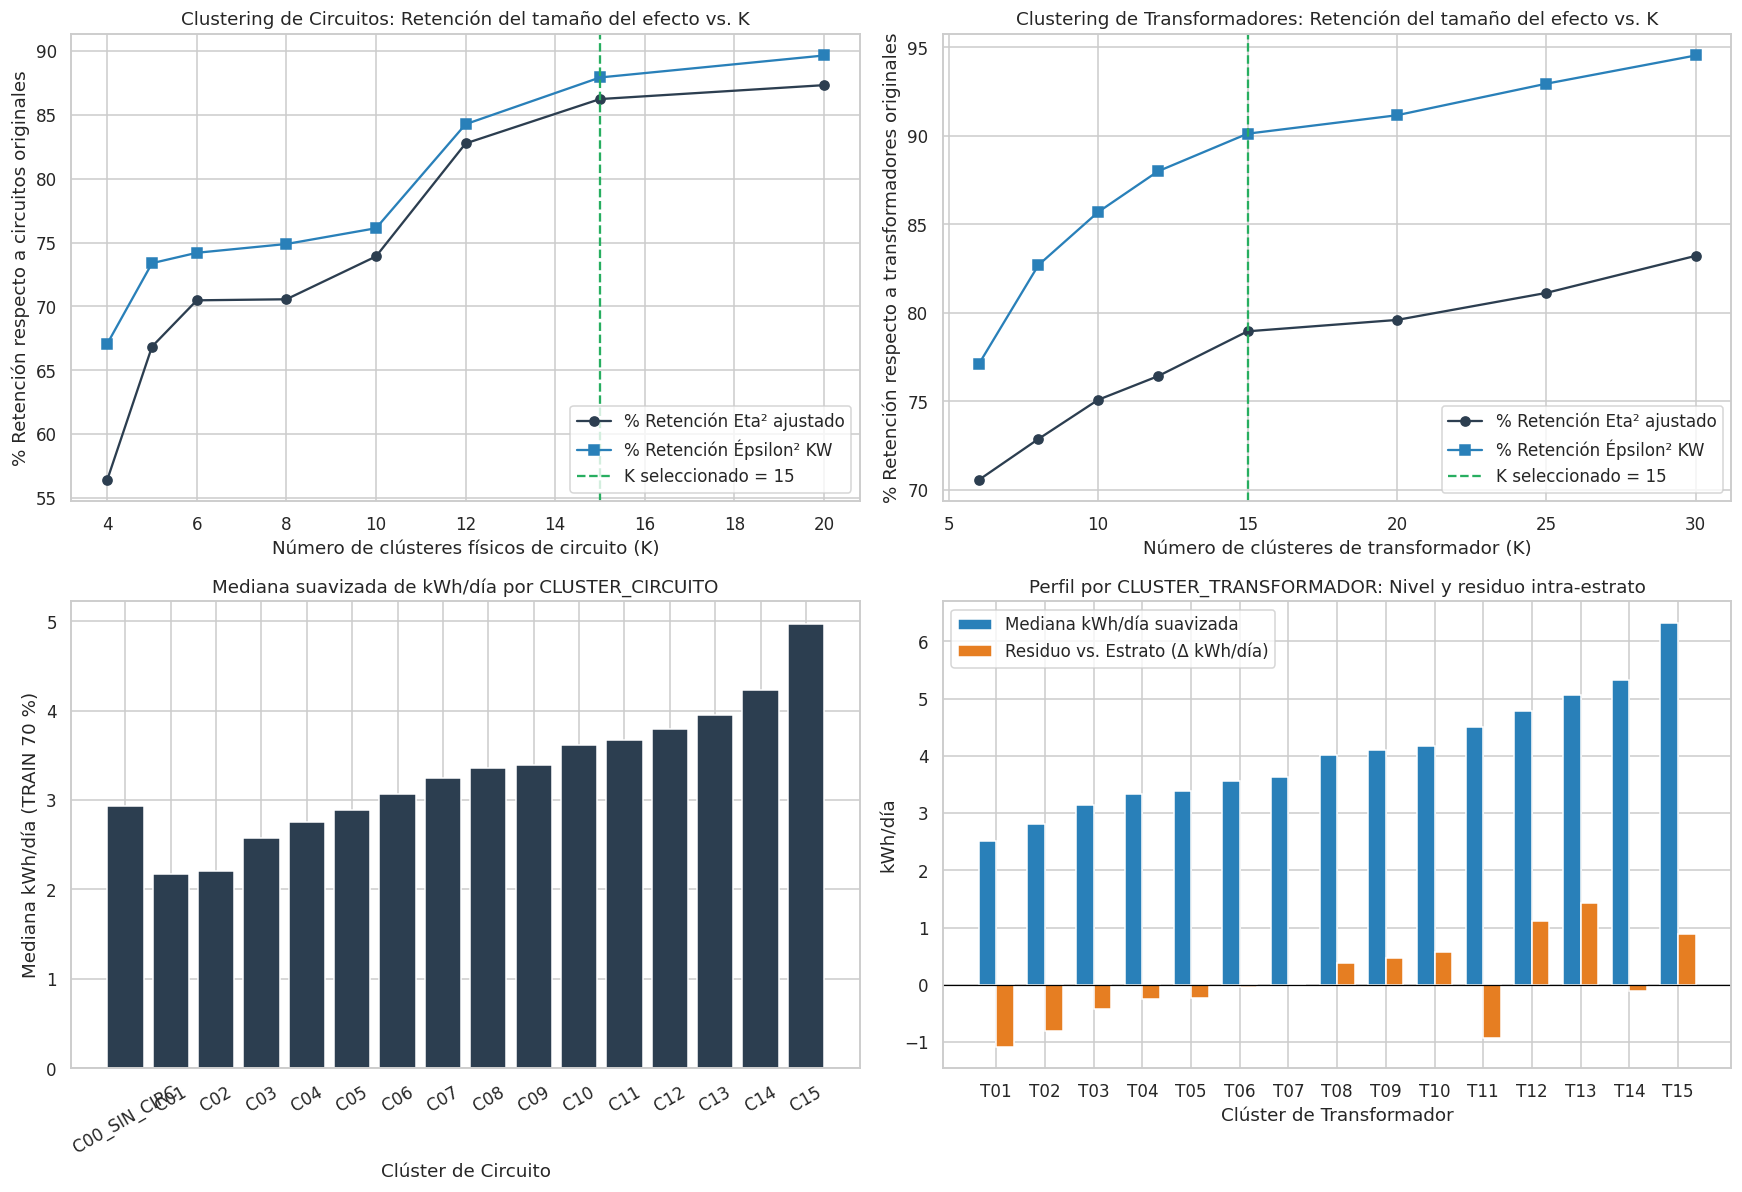

In [39]:
# Visualización de curvas de selección de K y perfiles de los clústeres mejorados
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Curva de retención de efecto para Circuitos
ax1 = axes[0, 0]
ax1.plot(df_eval_k_circ.index, df_eval_k_circ['Retencion_Eta2 (%)'], marker='o', color=PALETA[0], label='% Retención Eta² ajustado')
ax1.plot(df_eval_k_circ.index, df_eval_k_circ['Retencion_Epsilon2 (%)'], marker='s', color=PALETA[1], label='% Retención Épsilon² KW')
ax1.axvline(K_OPT_CIRC, color=PALETA[2], linestyle='--', label=f'K seleccionado = {K_OPT_CIRC}')
ax1.set_title('Clustering de Circuitos: Retención del tamaño del efecto vs. K')
ax1.set_xlabel('Número de clústeres físicos de circuito (K)')
ax1.set_ylabel('% Retención respecto a circuitos originales')
ax1.legend(loc='lower right')

# 2. Curva de retención de efecto para Transformadores
ax2 = axes[0, 1]
ax2.plot(df_eval_k_trafo.index, df_eval_k_trafo['Retencion_Eta2 (%)'], marker='o', color=PALETA[0], label='% Retención Eta² ajustado')
ax2.plot(df_eval_k_trafo.index, df_eval_k_trafo['Retencion_Epsilon2 (%)'], marker='s', color=PALETA[1], label='% Retención Épsilon² KW')
ax2.axvline(K_OPT_TRAFO, color=PALETA[2], linestyle='--', label=f'K seleccionado = {K_OPT_TRAFO}')
ax2.set_title('Clustering de Transformadores: Retención del tamaño del efecto vs. K')
ax2.set_xlabel('Número de clústeres de transformador (K)')
ax2.set_ylabel('% Retención respecto a transformadores originales')
ax2.legend(loc='lower right')

# 3. Perfil de consumo mediano por CLUSTER_CIRCUITO
ax3 = axes[1, 0]
ax3.bar(resumen_clusters_circuito.index, resumen_clusters_circuito['MEDIANA_KWH_DIA'], color=PALETA[0])
ax3.set_title('Mediana suavizada de kWh/día por CLUSTER_CIRCUITO')
ax3.set_xlabel('Clúster de Circuito')
ax3.set_ylabel('Mediana kWh/día (TRAIN 70 %)')
ax3.tick_params(axis='x', rotation=30)

# 4. Perfil de consumo mediano y residuo respecto al estrato por CLUSTER_TRANSFORMADOR
ax4 = axes[1, 1]
x_t = np.arange(len(resumen_clusters_trafo))
ax4.bar(x_t - 0.18, resumen_clusters_trafo['MEDIANA_KWH_DIA_SMOOTH'], width=0.36, color=PALETA[1], label='Mediana kWh/día suavizada')
ax4.bar(x_t + 0.18, resumen_clusters_trafo['MEDIANA_RESIDUAL_ESTRATO'], width=0.36, color=PALETA[3], label='Residuo vs. Estrato (Δ kWh/día)')
ax4.axhline(0, color='black', linewidth=0.8)
ax4.set_xticks(x_t)
ax4.set_xticklabels(resumen_clusters_trafo.index)
ax4.set_title('Perfil por CLUSTER_TRANSFORMADOR: Nivel y residuo intra-estrato')
ax4.set_xlabel('Clúster de Transformador')
ax4.set_ylabel('kWh/día')
ax4.legend()

plt.tight_layout()
guardar_figura(fig, '03_clustering_circuitos_y_transformadores_mejorado')
plt.show()

### 6.1 Exportación de catálogos (incluyendo variables continuas suavizadas sin fuga y banderas de atípicos)

In [40]:
os.makedirs(DIR_CATALOGOS, exist_ok=True)

# 1. Catálogo de Transformadores (etiquetas de clúster + métricas continuas suavizadas en TRAIN 70 % + banderas de Tukey)
catalogo_trafo = (
    df_trafo_estratos[[
        'CLUSTER_TRANSFORMADOR', 'CLUSTER_CIRCUITO',
        'ESTRATO_DOMINANTE', 'ESTRATO_PROMEDIO', 'PUREZA_ESTRATO_PCT', 'ENTROPIA_ESTRATO',
        'N_USUARIOS', 'N_USUARIOS_TRAIN',
        'KWH_DIA_MEDIANA_SMOOTH', 'RESIDUAL_ESTRATO_KWH', 'Z_INTRA_ESTRATO_KWH',
        'KWH_DIA_IQR_SMOOTH', 'PCT_CEROS_SMOOTH',
        'ATIPICO_USU_TUKEY_EXT', 'ATIPICO_CODIGO_BOLSA', 'ES_TRAFO_ATIPICO'
    ]]
    .reset_index()
)
ruta_cat_trafo = os.path.join(DIR_CATALOGOS, 'catalogo_clusters_transformador.parquet')
catalogo_trafo.to_parquet(ruta_cat_trafo, index=False)

# 2. Catálogo de Circuitos (incluyendo mapeo directo para cadena vacía "")
catalogo_circuito = (
    df_circuitos[[
        'CLUSTER_CIRCUITO', 'ESTRATO_DOMINANTE', 'ESTRATO_PROMEDIO',
        'PUREZA_ESTRATO_PCT', 'ENTROPIA_ESTRATO',
        'N_TRANSFORMADORES', 'N_USUARIOS', 'N_USUARIOS_TRAIN',
        'KWH_DIA_MEDIANA_SMOOTH', 'RESIDUAL_ESTRATO_KWH',
        'KWH_DIA_IQR_SMOOTH', 'IQR_MEDIANA_TRAFOS_SMOOTH', 'PCT_CEROS_SMOOTH',
        'ES_CIRCUITO_ATIPICO'
    ]]
    .reset_index()
    .rename(columns={'index': 'COD_CIRCUITO_LINEA', 'COD_CIRCUITO_CLEAN': 'COD_CIRCUITO_LINEA'})
)
if 'SIN_CIRCUITO' in df_circuitos.index:
    fila_vacia = catalogo_circuito.loc[catalogo_circuito['COD_CIRCUITO_LINEA'] == 'SIN_CIRCUITO'].copy()
    fila_vacia['COD_CIRCUITO_LINEA'] = ''
    catalogo_circuito = pd.concat([catalogo_circuito, fila_vacia], ignore_index=True)

ruta_cat_circ = os.path.join(DIR_CATALOGOS, 'catalogo_clusters_circuito.parquet')
catalogo_circuito.to_parquet(ruta_cat_circ, index=False)

# 3. Exportar los 3 DataFrames analíticos completos
df_trafo_consumo.reset_index().to_parquet(os.path.join(DIR_CATALOGOS, 'df_trafo_consumo.parquet'), index=False)
df_trafo_estratos.reset_index().to_parquet(os.path.join(DIR_CATALOGOS, 'df_trafo_estratos.parquet'), index=False)
df_circuitos.reset_index().rename(columns={'index': 'COD_CIRCUITO_LINEA', 'COD_CIRCUITO_CLEAN': 'COD_CIRCUITO_LINEA'}).to_parquet(
    os.path.join(DIR_CATALOGOS, 'df_circuitos.parquet'), index=False
)

print('Catálogos y DataFrames exportados exitosamente en:', DIR_CATALOGOS)
for nombre_arch in sorted(os.listdir(DIR_CATALOGOS)):
    tam_mb = os.path.getsize(os.path.join(DIR_CATALOGOS, nombre_arch)) / (1024 ** 2)
    print(f' - {nombre_arch}: {tam_mb:.2f} MB')

Catálogos y DataFrames exportados exitosamente en: /content/drive/MyDrive/Superintendencia/Catalogos_Categorias
 - catalogo_clusters_circuito.parquet: 0.09 MB
 - catalogo_clusters_transformador.parquet: 2.10 MB
 - df_circuitos.parquet: 0.30 MB
 - df_trafo_consumo.parquet: 3.57 MB
 - df_trafo_estratos.parquet: 5.40 MB
